# Mid-Fusion VLMs for Low-Level Image Quality Diagnostics — BLIP-2 (Q-Former) track

**Project:** Evaluating VLM Fusion Architectures for Low-Level Image Quality Diagnostics (NLP with LLMs).
**This notebook:** the *mid-fusion* arm — **BLIP-2 (ViT-g/14 → Q-Former with 32 learned queries → OPT-2.7B)**.

| Stage | What happens |
|---|---|
| 0 | Install pinned libs, config, download Q-Instruct (labels + image tar), Q-Bench (dev, labelled), BLIP-2 weights |
| 1 | **EDA** on Q-Instruct (task mix, answer lengths, sources, distortion vocabulary, MCQ answer-position bias, image resolutions, token lengths) and Q-Bench (type × concern) + **train/test leakage check** (perceptual hashing) |
| 2 | Load BLIP-2 with the **LLM in 4-bit NF4 (QLoRA)**, vision encoder frozen in fp16, Q-Former in fp32; architecture/parameter report |
| 3 | **Zero-shot** Q-Bench evaluation (option-likelihood scoring) + *blind* (no-image) control |
| 4 | **Bottleneck probing (zero-shot)** — controlled synthetic degradations (noise, blur, JPEG, over-smoothing, ringing) → feature sensitivity at ViT vs Q-Former, linear probes, and P(yes) "psychometric" curves |
| 5 | **PEFT setup**: LoRA on OPT (4-bit base) injected once; per-experiment reset of LoRA + Q-Former + projection |
| 6 | **All experiments**: train (time-budgeted, cosine LR, AMP fp16) → evaluate (+ blind) → probe → generate → save; then mean ± std / ablation tables and figures |
| 7 | Detailed analysis of the primary run: accuracy by type/concern, bootstrap CIs, McNemar, yes-bias, position bias, calibration (ECE), distortion-keyword error analysis, qualitative examples, bottleneck analysis |

**All experiments in ONE commit.** After the shared steps (downloads, EDA, model load, zero-shot evaluation and probing,
done once), section 6 trains and evaluates every experiment in `EXPERIMENTS` one after another, each starting from the
same zero-shot model (Q-Former/projection restored, LoRA re-initialised):

| Run | Seed | Trained parts | Extra data | Question it answers |
|---|---|---|---|---|
| `seed42_crossattn` (primary) | 42 | LoRA + Q-Former cross-attn + queries + projection | – | main result (detailed figures) |
| `seed42_none` | 42 | LoRA only (whole visual side frozen) | – | does adapting the bottleneck matter? |
| `seed42_full` | 42 | LoRA + whole Q-Former + queries + projection | – | is cross-attention enough? |
| `seed42_crossattn_synth` | 42 | as primary | +3k synthetic-distortion QA | is the ringing failure a data problem? |
| `seed43_crossattn`, `seed44_crossattn` | 43, 44 | as primary | – | seed variance (mean ± std) |

The data split (`DATA_SEED`) is fixed, so every run uses the same training pool, probe images and Q-Bench questions.
A time guard skips an experiment that would not finish before `TIME_LIMIT_HOURS`; one failing experiment does not stop the others.

**How to run on Kaggle:** Accelerator = *GPU T4 x2* (only GPU 0 is used), Internet = **On**, then
**Save Version → Save & Run All (Commit)**. Expected run time ≈ 5–5.5 h (Kaggle's limit is 12 h).
Optional: `SMOKE_TEST = True` + *Run All* interactively first (~20 min) to check everything end-to-end.

Outputs (`/kaggle/working/outputs/`): `summary.md` (all tables), `results_summary.json`, `aggregate_*.csv`, figures in `figs/`
(`agg_*` = comparisons across runs, the rest = primary run), and one folder per experiment in `runs/`.

In [1]:
# ---------------------------------------------------------------- 0.1 Install pinned libraries
import subprocess, sys, time
T0_NOTEBOOK = time.time()
PINNED = ["transformers==5.22.1", "peft==0.21.2", "bitsandbytes==0.50.2", "accelerate==1.15.0"]

def _pip(args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], capture_output=True, text=True)
    print("pip install", " ".join(args), "-> return code", r.returncode)
    if r.returncode != 0:
        print(r.stdout[-2000:]); print(r.stderr[-4000:])
    return r.returncode

if _pip(PINNED) != 0:
    print("Pinned install failed -> falling back to latest releases")
    _pip(["-U", "transformers", "peft", "bitsandbytes", "accelerate"])
# Kaggle ships torchao 0.10, which peft >= 0.21 rejects at LoRA-injection time. We don't use torchao -> remove it.
r = subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], capture_output=True, text=True)
print("pip uninstall torchao -> return code", r.returncode)
print(f"install done in {time.time() - T0_NOTEBOOK:.0f}s")

pip install transformers==5.22.1 peft==0.21.2 bitsandbytes==0.50.2 accelerate==1.15.0 -> return code 0
pip uninstall torchao -> return code 0
install done in 16s


In [2]:
# ---------------------------------------------------------------- 0.2 Imports & environment
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ.setdefault("HF_XET_CHUNK_CACHE_SIZE_BYTES", "0")          # no duplicate xet chunk cache on disk
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import io, re, gc, json, math, glob, random, shutil, tarfile, textwrap, traceback, warnings, contextlib
from collections import Counter, defaultdict
from multiprocessing import Pool

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from scipy import stats

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import transformers, peft
from transformers import AutoTokenizer, Blip2ForConditionalGeneration, BitsAndBytesConfig
from peft import LoraConfig, inject_adapter_in_model
import huggingface_hub
from huggingface_hub import hf_hub_download, snapshot_download

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

try:
    import bitsandbytes as bnb
    BNB_VERSION = bnb.__version__
except Exception as e:
    BNB_VERSION = f"unavailable ({e!r})"

print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__, "| bitsandbytes", BNB_VERSION, "| hub", huggingface_hub.__version__)
assert torch.cuda.is_available(), "No GPU! Set Accelerator = GPU T4 x2 in the Kaggle session options."
DEVICE = torch.device("cuda:0")
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"GPU{i}: {p.name} | {p.total_memory / 2**30:.1f} GB | sm_{p.major}{p.minor}")

python 3.13.16 | torch 2.11.0+cu130 | transformers 5.22.1 | peft 0.21.2 | bitsandbytes 0.50.2 | hub 1.33.0
GPU0: Tesla T4 | 14.6 GB | sm_75
GPU1: Tesla T4 | 14.6 GB | sm_75


In [3]:
# ---------------------------------------------------------------- 0.3 Configuration (ALL hyper-parameters live here)
SMOKE_TEST = False      # <-- True: ~20 min end-to-end check on tiny subsets.  False: the real run (commit this).

# ---- all experiments, run in this order (the FIRST one is the primary run used for the detailed analysis) ----
EXPERIMENTS = [
    dict(name="seed42_crossattn",       seed=42, train_qformer="crossattn", synth=False),
    dict(name="seed42_none",            seed=42, train_qformer="none",      synth=False),
    dict(name="seed42_full",            seed=42, train_qformer="full",      synth=False),
    dict(name="seed42_crossattn_synth", seed=42, train_qformer="crossattn", synth=True),
    dict(name="seed43_crossattn",       seed=43, train_qformer="crossattn", synth=False),
    dict(name="seed44_crossattn",       seed=44, train_qformer="crossattn", synth=False),
]
TIME_LIMIT_HOURS = 8.5          # safety limit (Kaggle allows 12 h): an experiment that would not finish before it is skipped
SEED = 42                       # global seed for the shared steps (training seeds are per experiment)
DATA_SEED = 42                  # fixed: same train pool / val / probe images / Q-Bench subset in every experiment
RUN_NAME = "all_experiments" + ("_SMOKE" if SMOKE_TEST else "")
ANY_SYNTH = any(e["synth"] for e in EXPERIMENTS)
assert all(e["train_qformer"] in ("none", "crossattn", "full") for e in EXPERIMENTS)
assert len({e["name"] for e in EXPERIMENTS}) == len(EXPERIMENTS), "experiment names must be unique"
MODEL_ID = "Salesforce/blip2-opt-2.7b"

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
OUT_DIR = os.path.join(WORK, "outputs")
FIG_DIR = os.path.join(OUT_DIR, "figs")
DATA_DIR = "/tmp/qdata"                       # big files stay OUT of /kaggle/working (20 GB output limit)
IMG_DIR = os.path.join(DATA_DIR, "images")
for d in (OUT_DIR, FIG_DIR, DATA_DIR, IMG_DIR):
    os.makedirs(d, exist_ok=True)

CFG = dict(
    run_name=RUN_NAME, experiments=EXPERIMENTS, time_limit_hours=TIME_LIMIT_HOURS, seed=SEED, data_seed=DATA_SEED,
    model_id=MODEL_ID, smoke_test=SMOKE_TEST, n_synth_images=1500, n_synth_examples=3000,
    # ---- data
    n_train_per_cat={"mcq": 5600, "yesno": 3400, "open_vqa": 2000, "description": 3000},   # pool; training is time-budgeted
    n_val_per_cat=60,
    val_image_frac=0.04, probe_pool_images=2500, n_probe_images=100,
    qbench_limit=None,                       # None = all 1,495 dev questions
    max_prompt_tokens=96, max_answer_tokens=128,
    # ---- PEFT (QLoRA)
    load_in_4bit=True, bnb_quant_type="nf4", bnb_double_quant=True,
    lora_r=16, lora_alpha=32, lora_dropout=0.05,
    lora_targets=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
    # ---- optimisation
    micro_bs=8, grad_accum=2,                # effective batch 16
    lr_lora=2e-4, lr_qformer=2e-5, lr_proj=5e-5,
    warmup_steps=30, min_lr_ratio=0.1, weight_decay=0.0, max_grad_norm=1.0, max_epochs=1,
    train_minutes=55.0, val_every_min=12.0, log_every=10,   # time cap per experiment (one epoch takes ~37 min)
    loss_weighting="per-sample mean over answer tokens",
    # ---- evaluation
    eval_item_bs=16, score_bs=32, num_workers=3, gen_max_new_tokens=60,
)
if SMOKE_TEST:
    CFG.update(n_train_per_cat={"mcq": 32, "yesno": 24, "open_vqa": 16, "description": 24}, n_val_per_cat=4,
               probe_pool_images=300, n_probe_images=4, qbench_limit=48, train_minutes=0.75, val_every_min=0.4,
               log_every=2, warmup_steps=3, n_synth_images=20, n_synth_examples=48)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
    json.dump(CFG, f, indent=2)
print(("*** SMOKE TEST MODE ***" if SMOKE_TEST else "*** FULL RUN ***"), "| run:", RUN_NAME, "| outputs ->", OUT_DIR)
print(json.dumps(CFG, indent=1))

# ---------------------------------------------------------------- shared utilities
RESULTS = {"run_name": RUN_NAME, "config": CFG}
FAILED_SECTIONS = []

def _json_default(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

def save_results():
    with open(os.path.join(OUT_DIR, "results_summary.json"), "w") as f:
        json.dump(RESULTS, f, indent=2, default=_json_default)

@contextlib.contextmanager
def section(name):
    """Non-critical sections: an exception is logged and the notebook keeps going (important for Commit runs)."""
    t0 = time.time()
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    try:
        yield
    except Exception as e:
        FAILED_SECTIONS.append((name, repr(e)))
        print(f"[WARN] section '{name}' failed: {e!r}")
        traceback.print_exc()
    finally:
        plt.close("all")
        print(f"[time] {name}: {time.time() - t0:.1f}s")

def savefig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout()
    plt.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close("all")
    print("saved", path)

def wrap(s, w=48):
    return "\n".join(textwrap.wrap(str(s), w))

def disk_report(tag=""):
    for p in ("/tmp", WORK):
        u = shutil.disk_usage(p)
        print(f"[disk{tag}] {p}: free {u.free / 2**30:.1f} GB / total {u.total / 2**30:.1f} GB")

*** FULL RUN *** | run: all_experiments | outputs -> /kaggle/working/outputs
{
 "run_name": "all_experiments",
 "experiments": [
  {
   "name": "seed42_crossattn",
   "seed": 42,
   "train_qformer": "crossattn",
   "synth": false
  },
  {
   "name": "seed42_none",
   "seed": 42,
   "train_qformer": "none",
   "synth": false
  },
  {
   "name": "seed42_full",
   "seed": 42,
   "train_qformer": "full",
   "synth": false
  },
  {
   "name": "seed42_crossattn_synth",
   "seed": 42,
   "train_qformer": "crossattn",
   "synth": true
  },
  {
   "name": "seed43_crossattn",
   "seed": 43,
   "train_qformer": "crossattn",
   "synth": false
  },
  {
   "name": "seed44_crossattn",
   "seed": 44,
   "train_qformer": "crossattn",
   "synth": false
  }
 ],
 "time_limit_hours": 8.5,
 "seed": 42,
 "data_seed": 42,
 "model_id": "Salesforce/blip2-opt-2.7b",
 "smoke_test": false,
 "n_synth_images": 1500,
 "n_synth_examples": 3000,
 "n_train_per_cat": {
  "mcq": 5600,
  "yesno": 3400,
  "open_vqa": 2000,


In [4]:
# ---------------------------------------------------------------- 0.4 Downloads (Q-Instruct labels + images, Q-Bench dev, BLIP-2)
QI_REPO, QB_REPO = "q-future/Q-Instruct-DB", "q-future/Q-Bench-HF"

def hf_get(repo, filename, repo_type="dataset", tries=4):
    for k in range(tries):
        try:
            return hf_hub_download(repo, filename, repo_type=repo_type, local_dir=DATA_DIR)
        except Exception as e:
            print(f"download {repo}/{filename} failed (attempt {k + 1}): {e!r}")
            time.sleep(10 * (k + 1))
    raise RuntimeError(f"could not download {repo}/{filename}")

disk_report(" before")
t = time.time(); LABELS_PATH = hf_get(QI_REPO, "cleaned_labels.json"); print(f"labels: {time.time() - t:.0f}s")
t = time.time(); QB_FILES = [hf_get(QB_REPO, f"data/dev-0000{i}-of-00003.parquet") for i in range(3)]; print(f"Q-Bench dev: {time.time() - t:.0f}s")
t = time.time(); TAR_PATH = hf_get(QI_REPO, "q-instruct-images.tar"); print(f"image tar ({os.path.getsize(TAR_PATH) / 2**30:.2f} GB): {time.time() - t:.0f}s")
t = time.time()
for k in range(4):
    try:
        MODEL_DIR = snapshot_download(MODEL_ID, allow_patterns=["*.json", "*.safetensors", "*.txt"])
        break
    except Exception as e:
        print(f"model download failed (attempt {k + 1}): {e!r}"); time.sleep(15 * (k + 1))
else:
    raise RuntimeError("could not download the model")
print(f"BLIP-2 weights: {time.time() - t:.0f}s -> {MODEL_DIR}")
disk_report(" after")

[disk before] /tmp: free 966.6 GB / total 8156.9 GB
[disk before] /kaggle/working: free 19.5 GB / total 19.5 GB


cleaned_labels.json: reconstructing file:   0%|          |  0.00B / 76.5MB            

cleaned_labels.json: downloading bytes:           |  0.00B            

labels: 1s


data/dev-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  393MB            

data/dev-00000-of-00003.parquet: downloading bytes:           |  0.00B            

... (7 outputs left out)

image tar (5.25 GB): 26s


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

BLIP-2 weights: 81s -> /root/.cache/huggingface/hub/models--Salesforce--blip2-opt-2.7b/snapshots/59a1ef6c1e5117b3f65523d1c6066825bcf315e3
[disk after] /tmp: free 946.3 GB / total 8156.9 GB
[disk after] /kaggle/working: free 19.5 GB / total 19.5 GB


In [5]:
# ---------------------------------------------------------------- 0.5 Pure helpers: text parsing, image preprocessing, distortions, hashing
# BLIP-2 image preprocessing (identical to BlipImageProcessor): RGB -> bicubic resize to 224x224 -> /255 -> CLIP mean/std
try:
    with open(os.path.join(MODEL_DIR, "preprocessor_config.json")) as f:
        _pp = json.load(f)
except Exception:
    _pp = {}
IMG_MEAN = np.array(_pp.get("image_mean", [0.48145466, 0.4578275, 0.40821073]), dtype=np.float32)
IMG_STD = np.array(_pp.get("image_std", [0.26862954, 0.26130258, 0.27577711]), dtype=np.float32)
_sz = _pp.get("size", {"height": 224, "width": 224})
IMG_SIZE = int(_sz.get("height", 224)) if isinstance(_sz, dict) else int(_sz)
print("image preprocessing:", IMG_SIZE, IMG_MEAN, IMG_STD)

def load_rgb(src):
    """src = file path or raw bytes."""
    im = Image.open(src if isinstance(src, str) else io.BytesIO(src))
    return im.convert("RGB")

def resize224(im):
    return im.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)

def preprocess(im):
    """PIL RGB -> float32 (3, S, S), normalised exactly like the BLIP-2 processor."""
    im = resize224(im) if im.size != (IMG_SIZE, IMG_SIZE) else im
    a = np.asarray(im, dtype=np.float32) / 255.0
    a = (a - IMG_MEAN) / IMG_STD
    return np.ascontiguousarray(a.transpose(2, 0, 1))

def dhash64(im):
    g = im.convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int(sum(1 << i for i, b in enumerate(bits) if b))

def thumb16(im):
    return np.asarray(im.convert("L").resize((16, 16), Image.BILINEAR), dtype=np.uint8).tobytes()

def img_info(path):
    """(width, height, format, dhash, 16x16 thumbnail) — runs in a worker pool."""
    try:
        im = Image.open(path)
        w, h, fmt = im.size[0], im.size[1], (im.format or "?")
        try:
            im.draft("L", (64, 64))
        except Exception:
            pass
        im = im.convert("L")
        return w, h, fmt, dhash64(im), thumb16(im)
    except Exception:
        return -1, -1, "BROKEN", -1, b""

OPT_RE = re.compile(r"^\s*([A-H])[\.\)]\s*(.+?)\s*$")
LETTER_RE = re.compile(r"^\s*\(?([A-H])\)?(?:[\.\):]|\s|$)")

def strip_image_tok(s):
    return re.sub(r"\s*<image>\s*", " ", s or "").strip()

def norm_opt(o):
    return re.sub(r"\s+", " ", str(o)).strip().rstrip(".").strip()

def parse_mcq(human):
    """'Question?\\nA. x\\nB. y\\nAnswer with the option's letter...' -> (question, [options])"""
    q_lines, opts = [], []
    for line in strip_image_tok(human).split("\n"):
        m = OPT_RE.match(line)
        if m and m.group(1) == chr(ord("A") + len(opts)):
            opts.append(m.group(2).strip())
        elif line.strip().lower().startswith("answer with the option"):
            continue
        elif not opts and line.strip():
            q_lines.append(line.strip())
    return " ".join(q_lines), opts

def first_qa(conv):
    human = gpt = None
    n_gpt = 0
    for c in conv or []:
        if c.get("from") == "human" and human is None:
            human = c.get("value", "")
        elif c.get("from") == "gpt":
            n_gpt += 1
            if gpt is None and human is not None:
                gpt = c.get("value", "")
    return human, gpt, n_gpt

def parse_record(rec):
    human, gpt, n_turns = first_qa(rec.get("conversations"))
    if human is None or gpt is None or not rec.get("image"):
        return None
    qtype, typ = rec.get("qtype"), rec.get("type")
    row = dict(image=rec["image"], qtype=qtype if qtype else "none", qtype_field=typ if typ else "none",
               n_turns=n_turns, answer_raw=gpt.strip(), options=None)
    if qtype == "mcq":
        q, opts = parse_mcq(human)
        m = LETTER_RE.match(gpt.strip())
        if not opts or m is None or (ord(m.group(1)) - ord("A")) >= len(opts):
            return None
        idx = ord(m.group(1)) - ord("A")
        row.update(question=q, options=[norm_opt(o) for o in opts], target=norm_opt(opts[idx]),
                   answer_idx=idx, category="mcq")
        return row
    q = " ".join(strip_image_tok(human).split())
    a = gpt.strip()
    a_low = a.lower().strip(" .!")
    if a_low in ("yes", "no"):
        row.update(question=q, options=["Yes", "No"], target=a_low.capitalize(), answer_idx=-1, category="yesno")
    elif len(a.split()) >= 15:
        row.update(question=q, target=a, answer_idx=-1, category="description")
    else:
        row.update(question=q, target=a, answer_idx=-1, category="open_vqa")
    return row

def make_prompt(question, options=None):
    """Single prompt template shared by training and evaluation (BLIP-2 VQA style)."""
    q = " ".join(str(question).split())
    if options:
        return f"Question: {q} Choices: {', '.join(options)}. Answer:"
    return f"Question: {q} Answer:"

# ---- controlled degradations applied at the model's input resolution (224x224) so the model *could* see them
DIST_LEVELS = {
    "noise":      [5, 10, 20, 35],          # additive Gaussian noise sigma (0-255 scale)  -> high-frequency noise
    "blur":       [0.6, 1.0, 1.6, 2.5],     # Gaussian blur radius (px)                     -> loss of sharpness
    "jpeg":       [60, 35, 18, 8],          # JPEG quality                                 -> blocking / compression
    "oversmooth": [3, 5, 7, 9],             # median filter size (edge-preserving)          -> texture loss ("oversmoothing")
    "ringing":    [0.70, 0.50, 0.35, 0.22], # ideal low-pass cut-off (fraction of Nyquist)  -> Gibbs ringing near edges
}
DIST_NAMES = list(DIST_LEVELS)
PSY_Q = {
    "noise": "Is there noticeable noise in this image?",
    "blur": "Is this image blurry?",
    "jpeg": "Are there compression artifacts in this image?",
    "oversmooth": "Does this image look over-smoothed, with fine texture details lost?",
    "ringing": "Are there ringing artifacts around the edges in this image?",
}
QUALITY_Q = "Is the quality of this image good?"

def ideal_lowpass(im, frac):
    a = np.asarray(im, dtype=np.float32)
    h, w = a.shape[:2]
    yy, xx = np.meshgrid(np.fft.fftfreq(h), np.fft.fftfreq(w), indexing="ij")
    mask = (np.sqrt(yy ** 2 + xx ** 2) <= 0.5 * frac).astype(np.float32)
    out = np.empty_like(a)
    for c in range(a.shape[2]):
        out[..., c] = np.real(np.fft.ifft2(np.fft.fft2(a[..., c]) * mask))
    return Image.fromarray(np.clip(out, 0, 255).round().astype(np.uint8))

def distort(im, kind, v, rng):
    if kind == "noise":
        a = np.asarray(im, dtype=np.float32) + rng.normal(0.0, v, size=(im.size[1], im.size[0], 3))
        return Image.fromarray(np.clip(a, 0, 255).round().astype(np.uint8))
    if kind == "blur":
        return im.filter(ImageFilter.GaussianBlur(radius=v))
    if kind == "jpeg":
        buf = io.BytesIO(); im.save(buf, format="JPEG", quality=int(v)); buf.seek(0)
        return Image.open(buf).convert("RGB")
    if kind == "oversmooth":
        return im.filter(ImageFilter.MedianFilter(size=int(v)))
    if kind == "ringing":
        return ideal_lowpass(im, v)
    raise ValueError(kind)

def make_variants(im224, seed):
    """[('clean', 0, img), (dist, level 1..4, img), ...] -> 21 variants."""
    rng = np.random.RandomState(seed)
    out = [("clean", 0, im224)]
    for kind, levels in DIST_LEVELS.items():
        for li, v in enumerate(levels):
            out.append((kind, li + 1, distort(im224, kind, v, rng)))
    return out

def find_near_dups(q_hash, q_thumb, t_hash, t_thumb, max_ham=6, max_mad=8.0):
    """Stage 1: dHash Hamming <= max_ham; stage 2 (confirmation): 16x16 thumbnails with mean |diff| <= max_mad.
    Returns, for every query image, the smallest thumbnail MAD among hash candidates (inf if none) -> dup if <= max_mad."""
    t = np.array([h & 0xFFFFFFFFFFFFFFFF for h in t_hash], dtype=np.uint64)
    T = np.stack([np.frombuffer(b, np.uint8) for b in t_thumb]).astype(np.float32) if len(t_thumb) else np.zeros((0, 256), np.float32)
    best = np.full(len(q_hash), np.inf)
    for i, (h, b) in enumerate(zip(q_hash, q_thumb)):
        if len(t) == 0:
            break
        x = np.bitwise_xor(t, np.uint64(h & 0xFFFFFFFFFFFFFFFF))
        ham = np.unpackbits(x.view(np.uint8)).reshape(-1, 64).sum(1)
        cand = np.where(ham <= max_ham)[0]
        if len(cand):
            q = np.frombuffer(b, np.uint8).astype(np.float32)
            best[i] = np.abs(T[cand] - q).mean(1).min()
    return best

def hamming_min(qhashes, thashes):
    """min Hamming distance from each query hash to the reference set (64-bit dHash)."""
    if len(thashes) == 0:
        return np.full(len(qhashes), 64)
    t = np.array([h & 0xFFFFFFFFFFFFFFFF for h in thashes], dtype=np.uint64)
    out = np.empty(len(qhashes), dtype=np.int64)
    for i, h in enumerate(qhashes):
        x = np.bitwise_xor(t, np.uint64(h & 0xFFFFFFFFFFFFFFFF))
        out[i] = np.unpackbits(x.view(np.uint8)).reshape(-1, 64).sum(1).min()
    return out

def load_train_image(r):
    """Training/validation image -> normalised array; synthetic-artifact records are distorted on the fly at 224x224."""
    im = load_rgb(r["path"])
    if r.get("dist"):
        im = distort(resize224(im), r["dist"][0], r["dist"][1], np.random.RandomState(r["seed"]))
    return preprocess(im)

print("helpers ready")

image preprocessing: 224 [0.48145467 0.4578275  0.40821072] [0.26862955 0.2613026  0.2757771 ]
helpers ready


Q-Instruct records: 200,534
example record: {
 "id": "8427827661_cauchy",
 "image": "spaq_koniq/8427827661.jpg",
 "conversations": [
  {
   "from": "human",
   "value": "Discuss and assess the quality of the picture, and form conclusions based on your evaluation.\n<image>"
  },
  {
   "from": "gpt",
   "value": "The lighting in this picture is average, with an overall dark color tone. The focus is on the people and children in the foreground, and the features of their clothes on the snowy ground are clear. The features of the person on the left and the cat on the right are difficult to discern due to underexposure. The features of the d
parsed: 200,534 usable | 0 skipped (unparseable MCQ / missing turns)
unique images: 18969

==================== EDA: Q-Instruct task mix ====================
   category   qtype qtype_field     n
description    none        none 53810
        mcq     mcq    what/how 38194
   open_vqa     vqa    what/how 34336
        mcq     mcq      yes/no 28794
      y

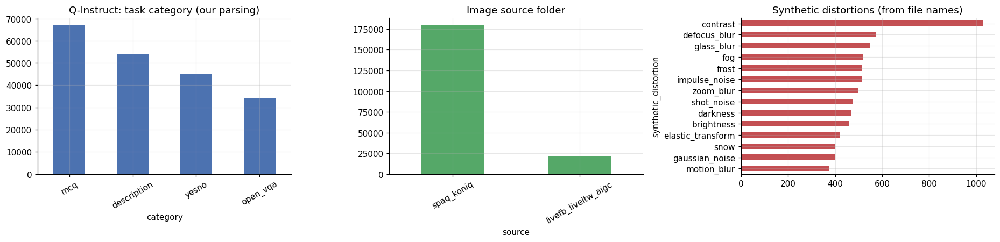

saved /kaggle/working/outputs/figs/eda_qinstruct_taskmix.png
[time] EDA: Q-Instruct task mix: 1.1s

==================== EDA: Q-Instruct lengths ====================


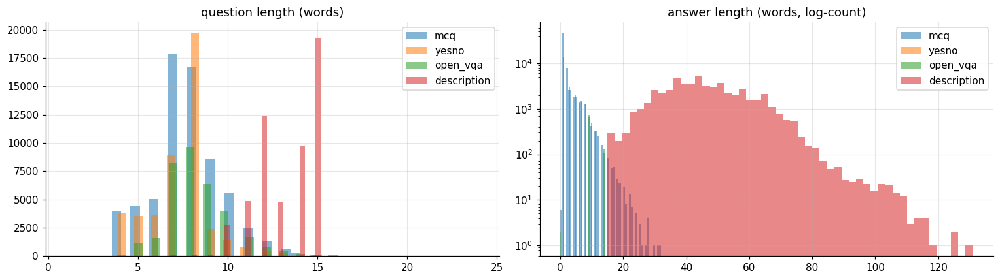

saved /kaggle/working/outputs/figs/eda_qinstruct_lengths.png
category       description      mcq  open_vqa    yesno
q_words count      54131.0  66988.0   34349.0  45066.0
        mean          13.3      7.7       8.3      7.3
        std            1.6      1.9       1.7      1.7
        min            5.0      3.0       1.0      3.0
        25%           12.0      7.0       7.0      7.0
        50%           14.0      8.0       8.0      8.0
        75%           15.0      9.0       9.0      8.0
        max           17.0     24.0      20.0     21.0
a_words count      54131.0  66988.0   34349.0  45066.0
        mean          46.2      2.1       3.1      1.0
        std           13.2      2.4       2.8      0.0
        min           15.0      0.0       0.0      1.0
        25%           37.0      1.0       1.0      1.0
        50%           45.0      1.0       2.0      1.0
        75%           55.0      2.0       4.0      1.0
        max          131.0     32.0      14.0      1.0
[tim

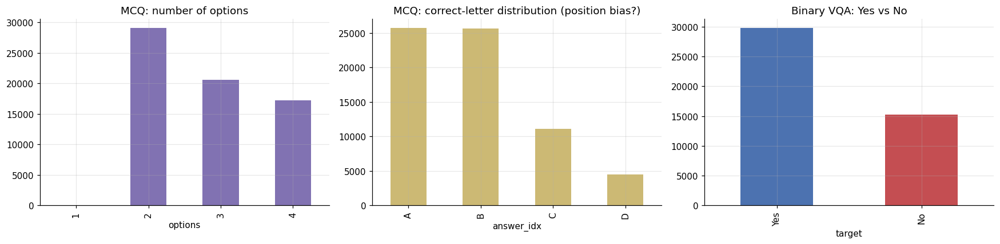

saved /kaggle/working/outputs/figs/eda_qinstruct_mcq_yesno.png
[time] EDA: MCQ / Yes-No balance: 0.8s

==================== EDA: low-level vocabulary in quality descriptions ====================


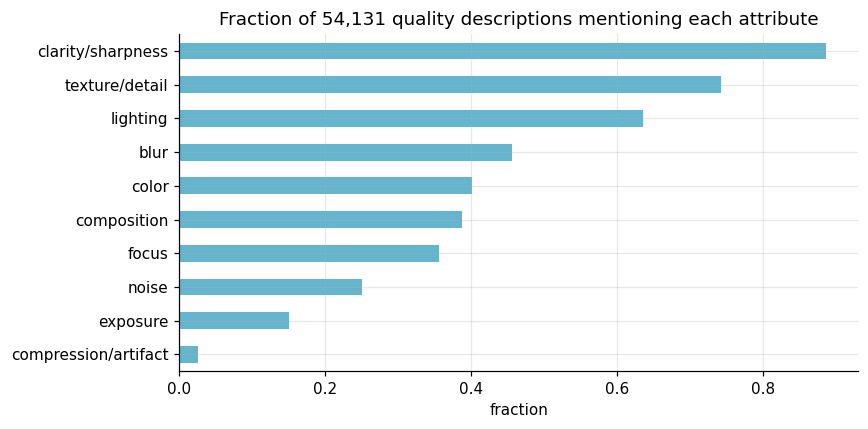

saved /kaggle/working/outputs/figs/eda_qinstruct_vocabulary.png
[time] EDA: low-level vocabulary in quality descriptions: 1.1s


In [6]:
# ---------------------------------------------------------------- 1.1 Q-Instruct: parse + EDA
with open(LABELS_PATH) as f:
    raw_labels = json.load(f)
print(f"Q-Instruct records: {len(raw_labels):,}")
print("example record:", json.dumps(raw_labels[0], indent=1)[:600])

rows = [parse_record(r) for r in raw_labels]
n_bad = sum(r is None for r in rows)
qi = pd.DataFrame([r for r in rows if r is not None])
del rows
qi["source"] = qi.image.str.split("/").str[0]
qi["q_words"] = qi.question.str.split().str.len()
qi["a_words"] = qi.target.str.split().str.len()
SYN_RE = re.compile(r"_(gaussian_noise|shot_noise|impulse_noise|speckle_noise|defocus_blur|glass_blur|motion_blur|zoom_blur|gaussian_blur|snow|frost|fog|brightness|darkness|contrast|elastic_transform|pixelate|jpeg_compression|jpeg|saturate|spatter)_\d", re.I)
qi["synthetic_distortion"] = qi.image.str.extract(SYN_RE, expand=False).fillna("none (authentic)")
print(f"parsed: {len(qi):,} usable | {n_bad:,} skipped (unparseable MCQ / missing turns)")
print("unique images:", qi.image.nunique())
RESULTS["qinstruct_eda"] = dict(n_records=len(raw_labels), n_usable=len(qi), n_images=int(qi.image.nunique()),
                                category_counts=qi.category.value_counts().to_dict(),
                                multi_turn=int((qi.n_turns > 1).sum()))
del raw_labels; gc.collect()

with section("EDA: Q-Instruct task mix"):
    display_cols = ["category", "qtype", "qtype_field"]
    print(qi.groupby(display_cols).size().rename("n").reset_index().sort_values("n", ascending=False).to_string(index=False))
    print("\nmulti-turn conversations (only the first QA pair is used):", int((qi.n_turns > 1).sum()))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    qi.category.value_counts().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Q-Instruct: task category (our parsing)")
    qi.source.value_counts().plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("Image source folder")
    qi[qi.synthetic_distortion != "none (authentic)"].synthetic_distortion.value_counts().head(15).plot.barh(ax=ax[2], color="#C44E52")
    ax[2].set_title("Synthetic distortions (from file names)"); ax[2].invert_yaxis()
    for a in ax[:2]:
        a.tick_params(axis="x", rotation=30)
    savefig("eda_qinstruct_taskmix")

with section("EDA: Q-Instruct lengths"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for c in ["mcq", "yesno", "open_vqa", "description"]:
        sub = qi[qi.category == c]
        ax[0].hist(sub.q_words.clip(upper=80), bins=40, alpha=0.55, label=c)
        ax[1].hist(sub.a_words.clip(upper=200), bins=50, alpha=0.55, label=c, log=True)
    ax[0].set_title("question length (words)"); ax[1].set_title("answer length (words, log-count)")
    ax[0].legend(); ax[1].legend()
    savefig("eda_qinstruct_lengths")
    print(qi.groupby("category")[["q_words", "a_words"]].describe().round(1).T)

with section("EDA: MCQ / Yes-No balance"):
    mcq = qi[qi.category == "mcq"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    mcq.options.str.len().value_counts().sort_index().plot.bar(ax=ax[0], color="#8172B2"); ax[0].set_title("MCQ: number of options")
    mcq.answer_idx.map(lambda i: "ABCDEFGH"[i]).value_counts().sort_index().plot.bar(ax=ax[1], color="#CCB974")
    ax[1].set_title("MCQ: correct-letter distribution (position bias?)")
    qi[qi.category == "yesno"].target.value_counts().plot.bar(ax=ax[2], color=["#4C72B0", "#C44E52"]); ax[2].set_title("Binary VQA: Yes vs No")
    savefig("eda_qinstruct_mcq_yesno")
    RESULTS["qinstruct_eda"]["yes_fraction"] = float((qi[qi.category == "yesno"].target == "Yes").mean())
    RESULTS["qinstruct_eda"]["mcq_letter_dist"] = mcq.answer_idx.value_counts(normalize=True).sort_index().round(3).to_dict()

with section("EDA: low-level vocabulary in quality descriptions"):
    KW = {"blur": r"blur", "noise": r"nois", "focus": r"focus", "exposure": r"expos|overexpos|underexpos",
          "lighting": r"light|bright|dark", "color": r"colou?r", "texture/detail": r"textur|detail",
          "clarity/sharpness": r"clarit|clear|sharp", "composition": r"compos", "compression/artifact": r"compress|artifact|block"}
    desc = qi[qi.category == "description"].target.str.lower()
    freq = {k: float(desc.str.contains(v).mean()) for k, v in KW.items()}
    pd.Series(freq).sort_values().plot.barh(figsize=(8, 4), color="#64B5CD")
    plt.title(f"Fraction of {len(desc):,} quality descriptions mentioning each attribute"); plt.xlabel("fraction")
    savefig("eda_qinstruct_vocabulary")
    RESULTS["qinstruct_eda"]["description_keyword_freq"] = freq

In [7]:
# ---------------------------------------------------------------- 1.2 Image-disjoint splits, stratified training subset, probe-image selection
rng = np.random.RandomState(DATA_SEED)
all_imgs = np.array(sorted(qi.image.unique()))
rng.shuffle(all_imgs)
n_val_img = max(20, int(CFG["val_image_frac"] * len(all_imgs)))
val_imgs = set(all_imgs[:n_val_img])
probe_pool = list(all_imgs[n_val_img:n_val_img + CFG["probe_pool_images"]])
train_imgs = set(all_imgs[n_val_img + CFG["probe_pool_images"]:])

def take(df, n, seed):
    return df.sample(n=min(n, len(df)), random_state=seed)

train_df = pd.concat([take(qi[(qi.category == c) & qi.image.isin(train_imgs)], n, DATA_SEED)
                      for c, n in CFG["n_train_per_cat"].items()]).sample(frac=1.0, random_state=DATA_SEED).reset_index(drop=True)
val_df = pd.concat([take(qi[(qi.category == c) & qi.image.isin(val_imgs)], CFG["n_val_per_cat"], DATA_SEED)
                    for c in CFG["n_train_per_cat"]]).reset_index(drop=True)

# probe images: "clean-looking" images (descriptions praise sharpness, no distortion words), never used in training
GOOD_KW = r"very clear|high clarity|excellent|very high|rich (?:texture|detail)|sharp|high definition|clear and"
BAD_KW = r"blur|nois|poor|low clarity|out of focus|overexpos|underexpos|dark|grain|artifact|compress|shak|lack|lost|loss"
pp_desc = qi[qi.image.isin(set(probe_pool)) & (qi.category == "description")].groupby("image").target.apply(lambda s: " ".join(s).lower())
good = pp_desc[pp_desc.str.contains(GOOD_KW) & ~pp_desc.str.contains(BAD_KW)].index.tolist()
good = [g for g in good if not SYN_RE.search(g)]
rng.shuffle(good)
good_set = set(good)
fill = [p for p in probe_pool if p not in good_set and not SYN_RE.search(p)]
probe_imgs = (good + fill)[:CFG["n_probe_images"]]
print(f"train pool rows {len(train_df):,} | val rows {len(val_df):,} | probe images {len(probe_imgs)} ({min(len(good), len(probe_imgs))} keyword-selected clean)")
print(train_df.category.value_counts().to_dict())
assert not (set(train_df.image) & set(val_df.image)) and not (set(train_df.image) & set(probe_imgs))

# images for the optional synthetic-artifact training data: clean-looking TRAINING images (never probe / val images)
synth_imgs = []
if ANY_SYNTH:
    tr_desc = qi[qi.image.isin(train_imgs) & (qi.category == "description")].groupby("image").target.apply(lambda s: " ".join(s).lower())
    cand = sorted(c for c in tr_desc[tr_desc.str.contains(GOOD_KW) & ~tr_desc.str.contains(BAD_KW)].index if not SYN_RE.search(c))
    rng.shuffle(cand)
    synth_imgs = cand[:CFG["n_synth_images"]]
    assert not (set(synth_imgs) & (set(probe_imgs) | val_imgs))
    print(f"synthetic-artifact source images: {len(synth_imgs)}")

train pool rows 14,000 | val rows 240 | probe images 100 (100 keyword-selected clean)
{'mcq': 5600, 'yesno': 3400, 'description': 3000, 'open_vqa': 2000}
synthetic-artifact source images: 1044


tar members indexed: 38,000 keys in 10s
extracted 9,862/9,862 images in 36s | missing 0
[disk] /tmp: free 948.7 GB / total 8156.9 GB
[disk] /kaggle/working: free 19.5 GB / total 19.5 GB
unreadable images: 0

==================== EDA: image resolution / format (training subset) ====================


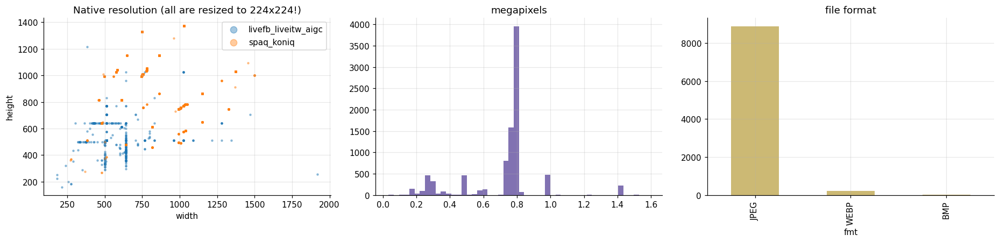

saved /kaggle/working/outputs/figs/eda_images_resolution.png
             w        h  megapixels
count  9144.00  9144.00     9144.00
mean    855.84   832.95        0.72
std     200.43   199.46        0.22
min     180.00   160.00        0.03
25%     747.00   768.00        0.74
50%     864.00   768.00        0.79
75%    1024.00  1008.00        0.79
max    1920.00  1372.00        1.59
median downscale factor to 224px (shorter side): 3.4x -> fine high-frequency artefacts are attenuated by the resize itself before the ViT sees them
[time] EDA: image resolution / format (training subset): 25.7s

==================== EDA: training examples ====================


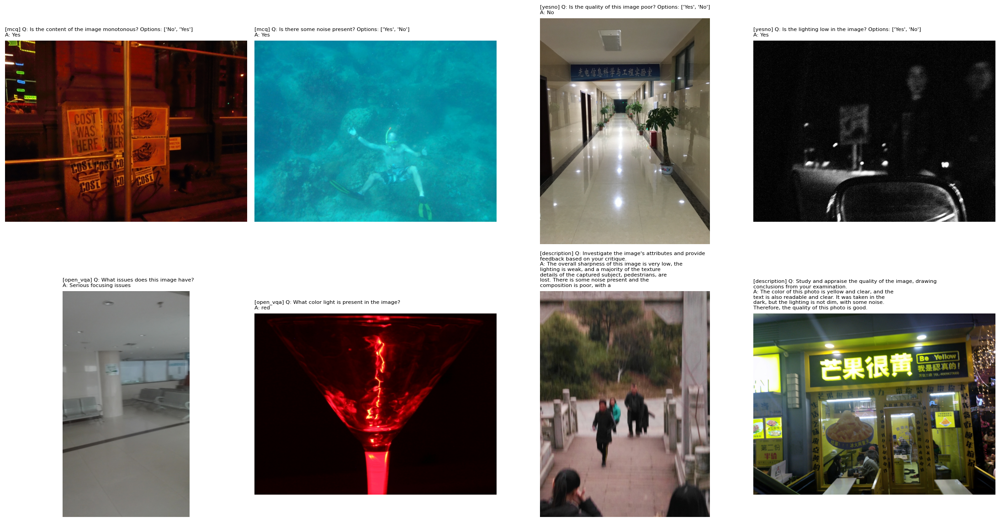

saved /kaggle/working/outputs/figs/eda_train_examples.png
[time] EDA: training examples: 4.0s


In [8]:
# ---------------------------------------------------------------- 1.3 Extract only the needed images from the 5.6 GB tar
def build_tar_index(tf):
    idx = {}
    for m in tf.getmembers():
        if not m.isfile():
            continue
        name = m.name.lstrip("./")
        parts = name.split("/")
        for k in range(len(parts)):
            idx.setdefault("/".join(parts[k:]), m)
    return idx

needed = sorted(set(train_df.image) | set(val_df.image) | set(probe_imgs) | set(synth_imgs))
t = time.time()
n_ok, missing = 0, []
with tarfile.open(TAR_PATH, "r:") as tf:
    tar_index = build_tar_index(tf)
    print(f"tar members indexed: {len(tar_index):,} keys in {time.time() - t:.0f}s")
    for rel in needed:
        m = tar_index.get(rel.lstrip("./")) or tar_index.get("/".join(rel.split("/")[-2:])) or tar_index.get(rel.split("/")[-1])
        if m is None:
            missing.append(rel); continue
        dst = os.path.join(IMG_DIR, rel)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        with tf.extractfile(m) as src, open(dst, "wb") as out:
            shutil.copyfileobj(src, out)
        n_ok += 1
print(f"extracted {n_ok:,}/{len(needed):,} images in {time.time() - t:.0f}s | missing {len(missing)}")
assert n_ok > 0.5 * len(needed), f"image extraction failed (only {n_ok}/{len(needed)}); first missing: {missing[:5]}"
os.remove(TAR_PATH)                                # free 5.6 GB
disk_report()

with Pool(4) as pool:
    infos = dict(zip(needed, pool.map(img_info, [os.path.join(IMG_DIR, r) for r in needed], chunksize=64)))
broken = {r for r, v in infos.items() if v[0] <= 0}
print("unreadable images:", len(broken))
def _ok(series):
    return series.map(lambda r: r in infos and r not in broken)
train_df, val_df = train_df[_ok(train_df.image)].reset_index(drop=True), val_df[_ok(val_df.image)].reset_index(drop=True)
probe_imgs = [p for p in probe_imgs if p in infos and p not in broken]
synth_imgs = [p for p in synth_imgs if p in infos and p not in broken]
for d in (train_df, val_df):
    d["path"] = d.image.map(lambda r: os.path.join(IMG_DIR, r))
RESULTS["data"] = dict(n_train_pool=len(train_df), n_val=len(val_df), n_probe_images=len(probe_imgs),
                       train_cat_counts=train_df.category.value_counts().to_dict(), n_train_images=int(train_df.image.nunique()))

with section("EDA: image resolution / format (training subset)"):
    info_df = pd.DataFrame([dict(image=r, w=v[0], h=v[1], fmt=v[2]) for r, v in infos.items() if r in set(train_df.image)])
    info_df["megapixels"] = info_df.w * info_df.h / 1e6
    info_df["source"] = info_df.image.str.split("/").str[0]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for s, g in info_df.groupby("source"):
        ax[0].scatter(g.w, g.h, s=4, alpha=0.4, label=s)
    ax[0].set_xlabel("width"); ax[0].set_ylabel("height"); ax[0].set_title("Native resolution (all are resized to 224x224!)"); ax[0].legend(markerscale=4)
    ax[1].hist(info_df.megapixels.clip(upper=15), bins=50, color="#8172B2"); ax[1].set_title("megapixels")
    info_df.fmt.value_counts().plot.bar(ax=ax[2], color="#CCB974"); ax[2].set_title("file format")
    savefig("eda_images_resolution")
    print(info_df[["w", "h", "megapixels"]].describe().round(2))
    print(f"median downscale factor to {IMG_SIZE}px (shorter side): {np.median(np.minimum(info_df.w, info_df.h) / IMG_SIZE):.1f}x"
          " -> fine high-frequency artefacts are attenuated by the resize itself before the ViT sees them")
    RESULTS["data"]["median_megapixels"] = float(info_df.megapixels.median())
    RESULTS["data"]["median_downscale_factor"] = float(np.median(np.minimum(info_df.w, info_df.h) / IMG_SIZE))

with section("EDA: training examples"):
    ex = pd.concat([train_df[train_df.category == c].head(2) for c in ["mcq", "yesno", "open_vqa", "description"]])
    fig, axes = plt.subplots(2, 4, figsize=(20, 10.5))
    for a, (_, r) in zip(axes.flat, ex.iterrows()):
        a.imshow(load_rgb(r.path)); a.axis("off")
        opts = f"\nOptions: {r.options}" if isinstance(r.options, list) else ""
        a.set_title(f"[{r.category}] Q: {wrap(r.question, 52)}{wrap(opts, 52)}\nA: {wrap(str(r.target)[:220], 52)}", fontsize=7.5, loc="left")
    savefig("eda_train_examples")

tokenizer: GPT2Tokenizer | BOS=2 EOS=2 PAD=1 | vocab=50266
built 3000 synthetic-artifact examples, e.g. 'Question: Which distortion is most visible in this image? Choices: Over-smoothing, Noise, Compression artifacts, Blur, Ringing. Answer:' -> 'Ringing' (('ringing', 0.22))
answer distribution: [('Yes', 1161), ('No', 1000), ('Blur', 193), ('Compression artifacts', 180), ('Ringing', 163), ('Over-smoothing', 156), ('Noise', 147)]
example training prompt: 'Question: Is the content of the image monotonous? Choices: No, Yes. Answer:' -> 'Yes'
decoded supervised tokens: ' Yes</s>'

==================== EDA: token lengths ====================


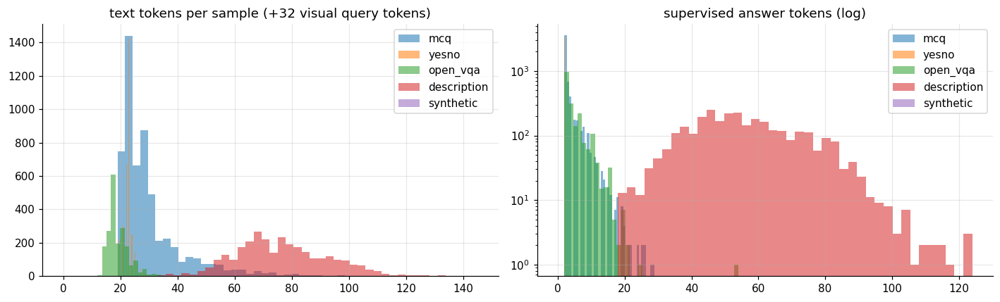

saved /kaggle/working/outputs/figs/eda_token_lengths.png
             total  answer
cat                       
description   76.6    56.2
mcq           30.2     3.4
open_vqa      19.3     4.9
yesno         22.6     2.0
truncated answers: 0
[time] EDA: token lengths: 2.3s


In [9]:
# ---------------------------------------------------------------- 1.4 Tokenisation of the training data (prompt masked, answer supervised)
tok = AutoTokenizer.from_pretrained(MODEL_DIR)
BOS = tok.bos_token_id if tok.bos_token_id is not None else 2
EOS = tok.eos_token_id if tok.eos_token_id is not None else 2
PAD = tok.pad_token_id if tok.pad_token_id is not None else 1
print(f"tokenizer: {type(tok).__name__} | BOS={BOS} EOS={EOS} PAD={PAD} | vocab={len(tok)}")

_enc_cache = {}
def enc(s):
    if s not in _enc_cache:
        _enc_cache[s] = tok(s, add_special_tokens=False)["input_ids"]
    return _enc_cache[s]

def prompt_ids(prompt):
    p = [BOS] + tok(prompt, add_special_tokens=False)["input_ids"]
    if len(p) > CFG["max_prompt_tokens"]:
        p = [BOS] + p[-(CFG["max_prompt_tokens"] - 1):]        # keep the end ("... Choices: ... Answer:")
    return p

def build_example(prompt, answer):
    p = prompt_ids(prompt)
    a = tok(" " + answer, add_special_tokens=False)["input_ids"]
    truncated = len(a) >= CFG["max_answer_tokens"]
    a = a[:CFG["max_answer_tokens"]] if truncated else a + [EOS]
    return p + a, [-100] * len(p) + a, truncated

CATS = ["mcq", "yesno", "open_vqa", "description", "synthetic"]

def to_records(df, seed):
    r_ = np.random.RandomState(seed)
    recs = []
    for row in df.itertuples():
        opts = list(row.options) if isinstance(row.options, list) else None
        if row.category == "yesno":
            opts = ["Yes", "No"] if r_.rand() < 0.5 else ["No", "Yes"]      # binary VQA -> 2-choice format used at test time
        ids, labels, trunc = build_example(make_prompt(row.question, opts), row.target)
        recs.append(dict(path=row.path, ids=ids, labels=labels, cat=CATS.index(row.category), truncated=trunc,
                         prompt=make_prompt(row.question, opts), target=row.target))
    return recs

train_recs = to_records(train_df, DATA_SEED)
val_recs = to_records(val_df, DATA_SEED + 1)

# ---- optional synthetic-artifact QA (training only). Question wording differs from the probe questions (PSY_Q)
SYNTH_TRAIN_Q = {
    "noise": ["Is there visible noise in the image?", "Does this picture look grainy or noisy?"],
    "blur": ["Is the image blurred?", "Does this photo lack sharpness because of blur?"],
    "jpeg": ["Does this image show JPEG compression artifacts?", "Are there blocky compression artifacts in the picture?"],
    "oversmooth": ["Has fine texture been smoothed away in this image?", "Does the picture look overly smooth, as if texture was erased?"],
    "ringing": ["Are there ripple-like ringing artifacts near the edges?", "Do you see halo or ringing patterns around edges?"],
}
SYNTH_NAMES = {"noise": "Noise", "blur": "Blur", "jpeg": "Compression artifacts", "oversmooth": "Over-smoothing", "ringing": "Ringing"}
SMOOTHING = {"blur", "oversmooth", "ringing", "jpeg"}      # visually confusable -> never used as each other's negatives

def synth_records(imgs, n, seed):
    r_ = np.random.RandomState(seed)
    recs = []
    for k in range(n):
        path = os.path.join(IMG_DIR, imgs[r_.randint(len(imgs))])
        clean = r_.rand() < 0.2
        kind = DIST_NAMES[r_.randint(len(DIST_NAMES))]
        level = 0 if clean else int(r_.randint(2, 5))                     # levels 2-4: clearly visible
        if clean or r_.rand() < 0.65:                                      # binary question
            if clean:
                ask, ans = DIST_NAMES[r_.randint(len(DIST_NAMES))], "No"
            elif r_.rand() < 0.75:                                         # ~50/50 Yes/No overall (clean images are always No)
                ask, ans = kind, "Yes"
            else:
                pool = ["noise"] if kind in SMOOTHING else [d for d in DIST_NAMES if d != "noise"]
                ask, ans = pool[r_.randint(len(pool))], "No"
            q, opts = SYNTH_TRAIN_Q[ask][r_.randint(2)], (["Yes", "No"] if r_.rand() < 0.5 else ["No", "Yes"])
        else:                                                              # which-distortion multiple choice
            q, ans = "Which distortion is most visible in this image?", SYNTH_NAMES[kind]
            opts = [SYNTH_NAMES[d] for d in r_.permutation(DIST_NAMES)]
        ids, labels, trunc = build_example(make_prompt(q, opts), ans)
        recs.append(dict(path=path, ids=ids, labels=labels, cat=CATS.index("synthetic"), truncated=trunc,
                         prompt=make_prompt(q, opts), target=ans,
                         dist=None if clean else (kind, DIST_LEVELS[kind][level - 1]), seed=int(seed * 100003 + k)))
    return recs

SYNTH_RECS = []                                   # added to the training pool only for experiments with synth=True
if ANY_SYNTH and synth_imgs:
    SYNTH_RECS = synth_records(synth_imgs, CFG["n_synth_examples"], DATA_SEED + 7)
    print(f"built {len(SYNTH_RECS)} synthetic-artifact examples, e.g. {SYNTH_RECS[0]['prompt']!r} -> {SYNTH_RECS[0]['target']!r} ({SYNTH_RECS[0]['dist']})")
    print("answer distribution:", Counter(r["target"] for r in SYNTH_RECS).most_common())
RESULTS["data"]["n_synth_examples"] = len(SYNTH_RECS)
print("example training prompt:", repr(train_recs[0]["prompt"]), "->", repr(train_recs[0]["target"][:120]))
print("decoded supervised tokens:", repr(tok.decode([t for t in train_recs[0]["labels"] if t != -100])))

with section("EDA: token lengths"):
    tl = pd.DataFrame(dict(cat=[CATS[r["cat"]] for r in train_recs], total=[len(r["ids"]) for r in train_recs],
                           answer=[sum(t != -100 for t in r["labels"]) for r in train_recs], trunc=[r["truncated"] for r in train_recs]))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for c in CATS:
        ax[0].hist(tl[tl.cat == c].total, bins=40, alpha=0.55, label=c)
        ax[1].hist(tl[tl.cat == c].answer, bins=40, alpha=0.55, label=c, log=True)
    ax[0].set_title("text tokens per sample (+32 visual query tokens)"); ax[1].set_title("supervised answer tokens (log)")
    ax[0].legend(); ax[1].legend()
    savefig("eda_token_lengths")
    print(tl.groupby("cat")[["total", "answer"]].mean().round(1)); print("truncated answers:", int(tl.trunc.sum()))
    RESULTS["data"]["mean_text_tokens"] = float(tl.total.mean()); RESULTS["data"]["n_truncated_answers"] = int(tl.trunc.sum())

Q-Bench dev rows: 1495 | columns: ['id', 'image', 'question', 'option0', 'option1', 'option2', 'option3', 'question_type', 'question_concern', 'correct_choice']
valid labelled questions: 1495 / 1495
type mapping: {2: 'How', 1: 'What', 0: 'Yes/No'} | yes/no-option fraction per code: {0: 0.99, 1: 0.01, 2: 0.0}
chance accuracy = 0.378

==================== EDA: Q-Bench ====================


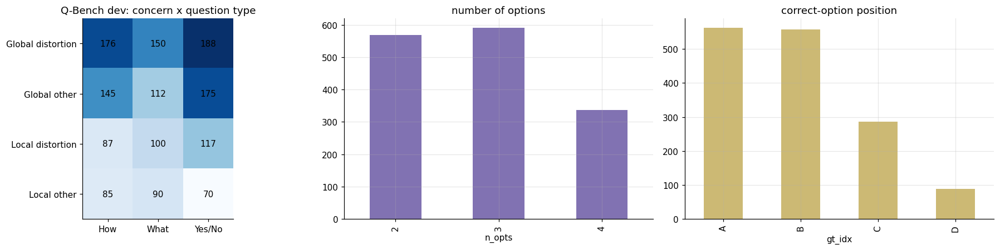

saved /kaggle/working/outputs/figs/eda_qbench.png
qtype              How  What  Yes/No
concern                             
Global distortion  176   150     188
Global other       145   112     175
Local distortion    87   100     117
Local other         85    90      70
Yes/No questions: GT=Yes fraction = 0.571
[time] EDA: Q-Bench: 0.6s

==================== EDA: Q-Bench examples ====================


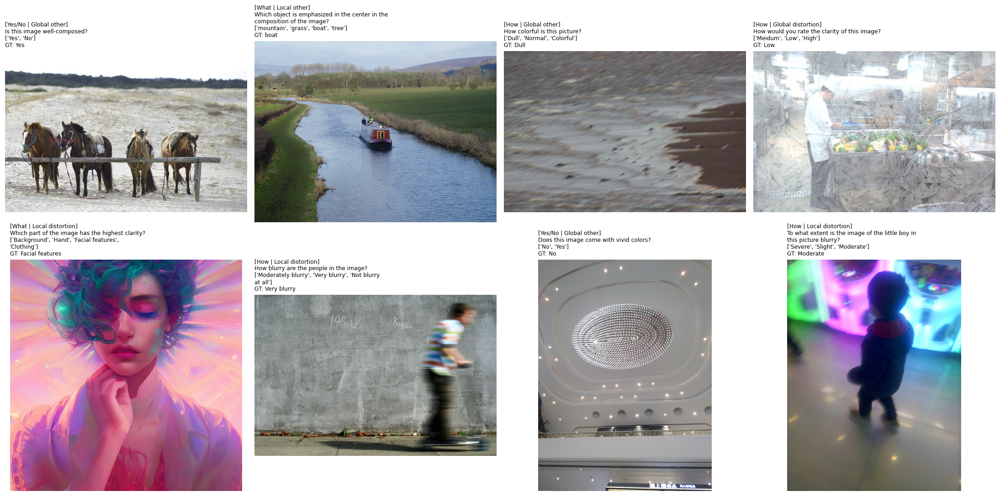

saved /kaggle/working/outputs/figs/eda_qbench_examples.png
[time] EDA: Q-Bench examples: 5.4s

==================== Leakage check: Q-Bench images vs training images (perceptual dHash) ====================
Q-Bench images with a confirmed near-duplicate in our training subset (dHash<=6 & thumbnail MAD<=8): 290 / 1495
[time] Leakage check: Q-Bench images vs training images (perceptual dHash): 53.4s


In [10]:
# ---------------------------------------------------------------- 1.5 Q-Bench (A1 perception, dev split = our held-out test set) + EDA
qb_raw = pd.concat([pd.read_parquet(f) for f in QB_FILES], ignore_index=True)
print("Q-Bench dev rows:", len(qb_raw), "| columns:", list(qb_raw.columns))

def qb_options(r):
    out = []
    for i in range(4):
        o = r.get(f"option{i}")
        if o is None or (isinstance(o, float) and np.isnan(o)) or str(o).strip() in ("", "N/A"):
            continue
        out.append(norm_opt(o))
    return out

def qb_gt(r, opts):
    c = str(r.get("correct_choice", "")).strip()
    if len(c) == 1 and c.upper() in "ABCD":
        i = ord(c.upper()) - ord("A")
        return i if i < len(opts) else -1
    c = norm_opt(c).lower()
    for i, o in enumerate(opts):
        if o.lower() == c:
            return i
    return -1

def qb_bytes(v):
    if isinstance(v, dict):
        return v.get("bytes")
    return v if isinstance(v, (bytes, bytearray)) else None

qb = pd.DataFrame(dict(qid=qb_raw["id"], question=qb_raw["question"].map(lambda s: " ".join(str(s).split())),
                       type_code=qb_raw["question_type"].astype(int), concern_code=qb_raw["question_concern"].astype(int)))
qb["options"] = [qb_options(r) for r in qb_raw.to_dict("records")]
qb["gt_idx"] = [qb_gt(r, o) for r, o in zip(qb_raw.to_dict("records"), qb.options)]
qb["img_bytes"] = qb_raw["image"].map(qb_bytes)
del qb_raw; gc.collect()
n_before = len(qb)
qb = qb[(qb.gt_idx >= 0) & (qb.options.str.len() >= 2) & qb.img_bytes.notna()].reset_index(drop=True)
print(f"valid labelled questions: {len(qb)} / {n_before}")

# question-type names are inferred from the data (robust to code conventions); concerns follow the Q-Bench / lmms-eval convention
_yn = qb.groupby("type_code").options.apply(lambda s: np.mean([set(o) <= {"Yes", "No"} for o in s]))
_how = qb.groupby("type_code").question.apply(lambda s: s.str.lower().str.startswith("how").mean())
yn_code = int(_yn.idxmax())
rest = [c for c in _how.index if c != yn_code]
how_code = int(_how[rest].idxmax()) if rest else -1
TYPE_NAMES = {int(c): ("Yes/No" if c == yn_code else "How" if c == how_code else "What") for c in qb.type_code.unique()}
CONCERN_NAMES = {0: "Global distortion", 1: "Global other", 2: "Local distortion", 3: "Local other"}
qb["qtype"] = qb.type_code.map(TYPE_NAMES)
qb["concern"] = qb.concern_code.map(CONCERN_NAMES).fillna("unknown")
qb["n_opts"] = qb.options.str.len()
print("type mapping:", TYPE_NAMES, "| yes/no-option fraction per code:", _yn.round(2).to_dict())
if CFG["qbench_limit"]:
    qb = qb.sample(n=min(CFG["qbench_limit"], len(qb)), random_state=DATA_SEED).reset_index(drop=True)
CHANCE = float((1.0 / qb.n_opts).mean())
RESULTS["qbench_eda"] = dict(n=len(qb), chance_acc=CHANCE, type_counts=qb.qtype.value_counts().to_dict(),
                             concern_counts=qb.concern.value_counts().to_dict(),
                             gt_letter_dist=qb.gt_idx.value_counts(normalize=True).sort_index().round(3).to_dict())
print(f"chance accuracy = {CHANCE:.3f}")

with section("EDA: Q-Bench"):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ct = pd.crosstab(qb.concern, qb.qtype)
    ax[0].imshow(ct.values, cmap="Blues")
    ax[0].set_xticks(range(ct.shape[1])); ax[0].set_xticklabels(ct.columns); ax[0].set_yticks(range(ct.shape[0])); ax[0].set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax[0].text(j, i, ct.values[i, j], ha="center", va="center")
    ax[0].set_title("Q-Bench dev: concern x question type"); ax[0].grid(False)
    qb.n_opts.value_counts().sort_index().plot.bar(ax=ax[1], color="#8172B2"); ax[1].set_title("number of options")
    qb.gt_idx.map(lambda i: "ABCD"[i]).value_counts().sort_index().plot.bar(ax=ax[2], color="#CCB974"); ax[2].set_title("correct-option position")
    savefig("eda_qbench")
    print(ct)
    print("Yes/No questions: GT=Yes fraction =", round(float((qb[qb.qtype == "Yes/No"].apply(lambda r: r.options[r.gt_idx], axis=1) == "Yes").mean()), 3))

with section("EDA: Q-Bench examples"):
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    for a, (_, r) in zip(axes.flat, qb.sample(8, random_state=1).iterrows()):
        a.imshow(load_rgb(r.img_bytes)); a.axis("off")
        a.set_title(f"[{r.qtype} | {r.concern}]\n{wrap(r.question, 50)}\n{wrap(r.options, 50)}\nGT: {r.options[r.gt_idx]}", fontsize=8, loc="left")
    savefig("eda_qbench_examples")

with section("Leakage check: Q-Bench images vs training images (perceptual dHash)"):
    _g = [load_rgb(b).convert("L") for b in qb.img_bytes]
    qb_hash, qb_thumb = [dhash64(g) for g in _g], [thumb16(g) for g in _g]
    del _g
    tr = [r for r in sorted(set(train_df.image)) if infos[r][3] >= 0]
    best_mad = find_near_dups(qb_hash, qb_thumb, [infos[r][3] for r in tr], [infos[r][4] for r in tr])
    qb["near_dup"] = best_mad <= 8.0
    print(f"Q-Bench images with a confirmed near-duplicate in our training subset (dHash<=6 & thumbnail MAD<=8): "
          f"{int(qb.near_dup.sum())} / {len(qb)}")
    RESULTS["leakage"] = dict(n_near_duplicates=int(qb.near_dup.sum()), rule="dHash Hamming<=6 and 16x16 thumbnail MAD<=8")
if "near_dup" not in qb:
    qb["near_dup"] = False
save_results()

In [11]:
# ---------------------------------------------------------------- 2.1 Load BLIP-2 (4-bit NF4 LLM, fp16 ViT, fp32 Q-Former) + architecture report
def load_blip2(quantize):
    kw = dict(dtype=torch.float16, device_map={"": 0})
    if quantize:
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type=CFG["bnb_quant_type"], bnb_4bit_use_double_quant=CFG["bnb_double_quant"],
            bnb_4bit_compute_dtype=torch.float16,                       # T4 has no bf16
            llm_int8_skip_modules=["vision_model", "qformer", "language_projection", "lm_head"])  # quantise ONLY the OPT LLM
    return Blip2ForConditionalGeneration.from_pretrained(MODEL_DIR, **kw)

t = time.time()
QUANT_MODE = "4bit-nf4" if CFG["load_in_4bit"] else "fp16"
try:
    model = load_blip2(CFG["load_in_4bit"])
except Exception as e:
    print(f"[WARN] 4-bit load failed ({e!r}) -> falling back to fp16 LLM (plain LoRA instead of QLoRA)")
    gc.collect(); torch.cuda.empty_cache()
    model = load_blip2(False); QUANT_MODE = "fp16 (fallback)"
model.eval()
model.config.use_cache = False
print(f"model loaded in {time.time() - t:.0f}s | LLM precision: {QUANT_MODE} | GPU mem {torch.cuda.memory_allocated() / 2**30:.2f} GB")
RESULTS["model"] = dict(quant_mode=QUANT_MODE)
VIS_DTYPE = model.vision_model.embeddings.patch_embedding.weight.dtype
NQ = model.config.num_query_tokens

def n_params(module):
    tot = 0
    for p in module.parameters():
        tot += p.numel() * (2 if p.__class__.__name__ == "Params4bit" else 1)   # 4-bit params are packed 2-per-byte
    return tot

def count_4bit(module):
    return sum(1 for m in module.modules() if m.__class__.__name__ == "Linear4bit")

vc, qc, tc = model.config.vision_config, model.config.qformer_config, model.config.text_config
n_patches = (vc.image_size // vc.patch_size) ** 2 + 1
arch = pd.DataFrame([
    dict(module="vision_model (EVA ViT-g/14)", params_M=n_params(model.vision_model) / 1e6, linear4bit=count_4bit(model.vision_model),
         dtype=str(VIS_DTYPE), role=f"{n_patches} tokens x {vc.hidden_size}d, {vc.num_hidden_layers} layers — frozen"),
    dict(module="query_tokens", params_M=model.query_tokens.numel() / 1e6, linear4bit=0, dtype=str(model.query_tokens.dtype),
         role=f"{NQ} learned queries x {qc.hidden_size}d"),
    dict(module="qformer (BERT-base + x-attn)", params_M=n_params(model.qformer) / 1e6, linear4bit=count_4bit(model.qformer),
         dtype=str(next(model.qformer.parameters()).dtype),
         role=f"{qc.num_hidden_layers} layers, cross-attn every {qc.cross_attention_frequency} -> {NQ} x {qc.hidden_size}d"),
    dict(module="  of which cross-attention", params_M=sum(p.numel() for n, p in model.qformer.named_parameters() if "crossattention" in n) / 1e6,
         linear4bit=0, dtype="", role="the mid-fusion bottleneck (trained)"),
    dict(module="language_projection", params_M=n_params(model.language_projection) / 1e6, linear4bit=count_4bit(model.language_projection),
         dtype=str(model.language_projection.weight.dtype), role=f"{qc.hidden_size} -> {tc.hidden_size}"),
    dict(module="language_model (OPT-2.7B)", params_M=n_params(model.language_model) / 1e6, linear4bit=count_4bit(model.language_model),
         dtype=QUANT_MODE, role=f"{tc.num_hidden_layers} layers, d={tc.hidden_size}, vocab={tc.vocab_size}"),
])
print(arch.round(2).to_string(index=False))
comp = (n_patches * vc.hidden_size) / (NQ * qc.hidden_size)
print(f"\nMid-fusion bottleneck: {n_patches}x{vc.hidden_size} = {n_patches * vc.hidden_size:,} visual floats  ->  {NQ}x{qc.hidden_size} = "
      f"{NQ * qc.hidden_size:,} query floats  ({comp:.1f}x compression, {n_patches / NQ:.1f}x fewer tokens)")
print(f"GPU memory footprint: {model.get_memory_footprint() / 2**30:.2f} GB")
arch.to_csv(os.path.join(OUT_DIR, "architecture.csv"), index=False)
RESULTS["model"].update(arch=arch.round(3).to_dict("records"), compression_ratio=comp, vit_tokens=n_patches, query_tokens=NQ,
                        footprint_gb=model.get_memory_footprint() / 2**30)
if count_4bit(model.vision_model) > 0:
    print("[WARN] the vision encoder was quantised (unexpected) — results remain valid but note it in the report")

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

model loaded in 54s | LLM precision: 4bit-nf4 | GPU mem 3.69 GB
                      module  params_M  linear4bit         dtype                                       role
 vision_model (EVA ViT-g/14)    985.95           0 torch.float16     257 tokens x 1408d, 39 layers — frozen
                query_tokens      0.02           0 torch.float32                  32 learned queries x 768d
qformer (BERT-base + x-attn)    105.14           0 torch.float32 12 layers, cross-attn every 2 -> 32 x 768d
    of which cross-attention     20.08           0                      the mid-fusion bottleneck (trained)
         language_projection      1.97           0 torch.float16                                768 -> 2560
   language_model (OPT-2.7B)   2651.68         192      4bit-nf4             32 layers, d=2560, vocab=50304

Mid-fusion bottleneck: 257x1408 = 361,856 visual floats  ->  32x768 = 24,576 query floats  (14.7x compression, 8.0x fewer tokens)
GPU memory footprint: 3.66 GB


In [12]:
# ---------------------------------------------------------------- 2.2 Core model functions (manual fusion forward — version-independent)
def encode(pix, with_grad=False):
    """pixels -> (ViT tokens, Q-Former query outputs, LLM-space soft prompts). Mirrors Blip2ForConditionalGeneration.get_image_features."""
    pix = pix.to(DEVICE, non_blocking=True).to(VIS_DTYPE)
    with torch.no_grad():                                                   # ViT always frozen
        vit = model.vision_model(pixel_values=pix).last_hidden_state       # (B, 257, 1408) fp16
    ctx = contextlib.nullcontext() if with_grad else torch.no_grad()
    with ctx:
        q = model.query_tokens.expand(vit.shape[0], -1, -1)
        att = torch.ones(vit.shape[:-1], dtype=torch.long, device=vit.device)
        qf = model.qformer(query_embeds=q, encoder_hidden_states=vit, encoder_attention_mask=att).last_hidden_state  # (B, 32, 768) fp32
        proj = model.language_projection(qf.to(model.language_projection.weight.dtype))                              # (B, 32, 2560)
    return vit, qf, proj

def lm_logits(proj, ids, am):
    """[32 visual soft-prompt tokens | text tokens] -> OPT logits (B, 32+T, V)."""
    lm = model.language_model
    with torch.autocast("cuda", dtype=torch.float16):
        txt = lm.get_input_embeddings()(ids)
        emb = torch.cat([proj.to(txt.dtype), txt], dim=1)
        full_am = torch.cat([torch.ones(ids.shape[0], proj.shape[1], dtype=am.dtype, device=am.device), am], dim=1)
        out = lm(inputs_embeds=emb, attention_mask=full_am, use_cache=False)
    return out.logits

def per_sample_loss(pix, ids, labels, am, with_grad):
    _, _, proj = encode(pix, with_grad=with_grad)
    logits = lm_logits(proj, ids, am)
    lg = logits[:, proj.shape[1]:-1].float()                                 # position Q+j predicts text token j+1
    tgt = labels[:, 1:]
    ce = F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1), ignore_index=-100, reduction="none").view(tgt.shape)
    m = (tgt != -100).float()
    return (ce * m).sum(1) / m.sum(1).clamp(min=1.0)

@torch.no_grad()
def score_options(proj, pids_list, options_list, bs=None):
    """Option-likelihood scoring. Returns (sum log-prob, mean log-prob per token) for each option of each item."""
    bs = bs or CFG["score_bs"]
    flat = []
    for i, (p, opts) in enumerate(zip(pids_list, options_list)):
        for j, o in enumerate(opts):
            flat.append((i, j, p, enc(" " + o) or [EOS]))
    sums = [[0.0] * len(o) for o in options_list]
    means = [[0.0] * len(o) for o in options_list]
    for s in range(0, len(flat), bs):
        chunk = flat[s:s + bs]
        L = max(len(p) + len(o) for _, _, p, o in chunk)
        ids = torch.full((len(chunk), L), PAD, dtype=torch.long)
        am = torch.zeros((len(chunk), L), dtype=torch.long)
        cm = torch.zeros((len(chunk), L), dtype=torch.float32)
        for k, (_, _, p, o) in enumerate(chunk):
            seq = p + o
            ids[k, :len(seq)] = torch.tensor(seq); am[k, :len(seq)] = 1; cm[k, len(p):len(seq)] = 1
        ids, am, cm = ids.to(DEVICE), am.to(DEVICE), cm.to(DEVICE)
        logits = lm_logits(proj[[i for i, _, _, _ in chunk]], ids, am)
        lp = torch.log_softmax(logits[:, proj.shape[1]:-1].float(), dim=-1).gather(-1, ids[:, 1:, None]).squeeze(-1)
        m = cm[:, 1:]
        tot = (lp * m).sum(1).tolist(); cnt = m.sum(1).clamp(min=1).tolist()
        for k, (i, j, _, _) in enumerate(chunk):
            sums[i][j] = tot[k]; means[i][j] = tot[k] / cnt[k]
    return sums, means

@torch.no_grad()
def generate(proj1, prompt, max_new=None, rep_penalty=1.15):
    """Greedy decoding (no KV cache; fine for a handful of qualitative examples)."""
    max_new = max_new or CFG["gen_max_new_tokens"]
    ids, out = prompt_ids(prompt), []
    for _ in range(max_new):
        t = torch.tensor([ids + out], device=DEVICE)
        logits = lm_logits(proj1, t, torch.ones_like(t))[0, -1].float()
        for tid in set(out):
            logits[tid] = logits[tid] / rep_penalty if logits[tid] > 0 else logits[tid] * rep_penalty
        nxt = int(logits.argmax())
        if nxt == EOS:
            break
        out.append(nxt)
    txt = tok.decode(out, skip_special_tokens=True).strip()
    return txt.split("Question:")[0].strip()

class ImgDS(Dataset):
    def __init__(self, srcs):
        self.srcs = list(srcs)
    def __len__(self):
        return len(self.srcs)
    def __getitem__(self, i):
        try:
            a = preprocess(load_rgb(self.srcs[i]))
        except Exception:
            a = np.zeros((3, IMG_SIZE, IMG_SIZE), np.float32)
        return torch.from_numpy(a), i

GRAY_PIX = torch.from_numpy(preprocess(Image.new("RGB", (IMG_SIZE, IMG_SIZE), (128, 128, 128))))[None]

def eval_qbench(tag, blind=False, out_dir=None):
    """Scores every option of every Q-Bench question. blind=True replaces every image by a uniform gray image."""
    model.eval()
    t0 = time.time()
    pids = [prompt_ids(make_prompt(q, o)) for q, o in zip(qb.question, qb.options)]
    all_s, all_m = [None] * len(qb), [None] * len(qb)
    if blind:
        _, _, gproj = encode(GRAY_PIX)
    loader = DataLoader(ImgDS(qb.img_bytes.tolist()), batch_size=CFG["eval_item_bs"], shuffle=False, num_workers=CFG["num_workers"])
    with torch.no_grad():
        for bi, (pix, idx) in enumerate(loader):
            idx = idx.tolist()
            proj = gproj.expand(len(idx), -1, -1) if blind else encode(pix)[2]
            s, m = score_options(proj, [pids[i] for i in idx], [qb.options[i] for i in idx])
            for k, i in enumerate(idx):
                all_s[i], all_m[i] = s[k], m[k]
            if bi % 20 == 0:
                print(f"  [{tag}] {min((bi + 1) * CFG['eval_item_bs'], len(qb))}/{len(qb)}  {time.time() - t0:.0f}s")
    return build_pred_df(tag, all_s, all_m, time.time() - t0, out_dir)

def build_pred_df(tag, all_s, all_m, secs=0.0, out_dir=None):
    df = qb[["qid", "question", "options", "gt_idx", "qtype", "concern", "n_opts", "near_dup"]].copy()
    df["scores_sum"], df["scores_mean"] = all_s, all_m
    df["pred_mean"] = [int(np.argmax(m)) for m in all_m]
    df["pred_sum"] = [int(np.argmax(s)) for s in all_s]
    df["correct"] = df.pred_mean == df.gt_idx                    # primary rule: length-normalised log-likelihood
    df["correct_sum"] = df.pred_sum == df.gt_idx
    df["probs"] = [list(np.exp(np.array(s) - np.max(s)) / np.exp(np.array(s) - np.max(s)).sum()) for s in all_s]
    df["conf"] = [max(p) for p in df.probs]
    df["model"] = tag
    print(f"[{tag}] acc(mean-norm) = {df.correct.mean():.4f} | acc(sum) = {df.correct_sum.mean():.4f} | {secs:.0f}s")
    df.drop(columns=["options"]).to_csv(os.path.join(out_dir or OUT_DIR, f"qbench_preds_{tag}.csv"), index=False)
    return df

def qbench_summary(df, col="correct"):
    out = {"overall": float(df[col].mean()), "n": int(len(df))}
    for k in ("qtype", "concern"):
        out.update({f"{k}:{g}": float(v) for g, v in df.groupby(k)[col].mean().items()})
    return out
print("core functions ready")

core functions ready


In [13]:
# ---------------------------------------------------------------- 3. Zero-shot evaluation on Q-Bench (+ blind control)
zs_df = eval_qbench("zeroshot")
RESULTS["qbench_zeroshot"] = qbench_summary(zs_df)
RESULTS["qbench_zeroshot_sumrule"] = qbench_summary(zs_df, "correct_sum")
zs_blind_df = None
with section("Zero-shot blind (gray image) control"):
    zs_blind_df = eval_qbench("zeroshot_blind", blind=True)
    RESULTS["qbench_zeroshot_blind"] = qbench_summary(zs_blind_df)
print(pd.Series(RESULTS["qbench_zeroshot"]).round(4))
save_results()

  [zeroshot] 16/1495  7s
  [zeroshot] 336/1495  38s
  [zeroshot] 656/1495  73s
  [zeroshot] 976/1495  111s
  [zeroshot] 1296/1495  148s
[zeroshot] acc(mean-norm) = 0.4241 | acc(sum) = 0.4194 | 172s

==================== Zero-shot blind (gray image) control ====================
  [zeroshot_blind] 16/1495  3s
  [zeroshot_blind] 336/1495  28s
  [zeroshot_blind] 656/1495  51s
  [zeroshot_blind] 976/1495  75s
  [zeroshot_blind] 1296/1495  100s
[zeroshot_blind] acc(mean-norm) = 0.3987 | acc(sum) = 0.3853 | 116s
[time] Zero-shot blind (gray image) control: 115.8s
overall                         0.4241
n                            1495.0000
qtype:How                       0.3428
qtype:What                      0.3650
qtype:Yes/No                    0.5455
concern:Global distortion       0.3872
concern:Global other            0.4468
concern:Local distortion        0.4145
concern:Local other             0.4735
dtype: float64



==================== Probing (zero-shot) ====================
  [probe zeroshot] image 1/100  3s
  [probe zeroshot] image 21/100  68s
  [probe zeroshot] image 41/100  133s
  [probe zeroshot] image 61/100  198s
  [probe zeroshot] image 81/100  263s
[probe zeroshot] done in 325s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.6017288058996201, 'proj': 0.3003906041383743}
[time] Probing (zero-shot): 324.8s

==================== Figure: distortion examples ====================


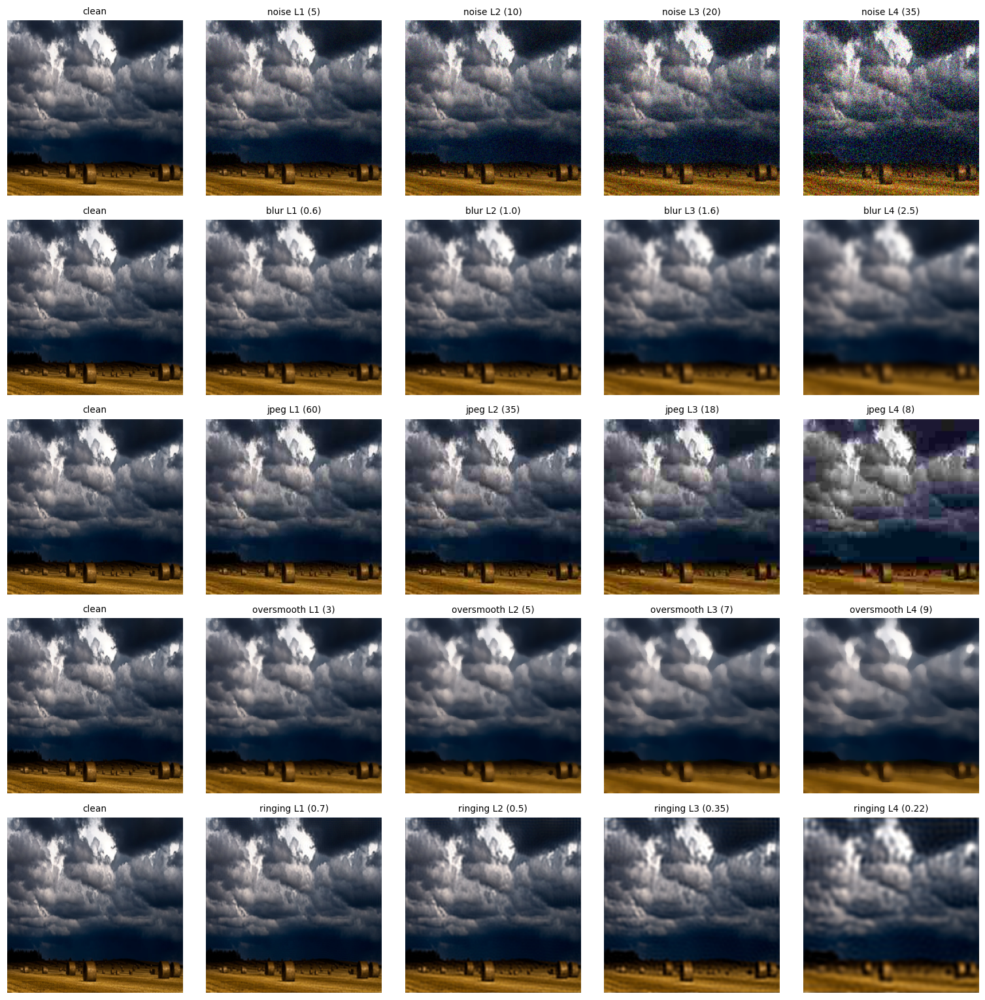

saved /kaggle/working/outputs/figs/probe_distortion_examples.png
[time] Figure: distortion examples: 4.3s


In [14]:
# ---------------------------------------------------------------- 4. Bottleneck probing: controlled degradations (zero-shot)
PROBE_224 = [resize224(load_rgb(os.path.join(IMG_DIR, p))) for p in probe_imgs]

@torch.no_grad()
def run_probe(tag):
    model.eval()
    t0 = time.time()
    sens, meta, psy = [], [], []
    feats = {"vit": [], "qf": []}
    clean_tok = {"vit": [], "qf": [], "proj": []}
    for ii, img in enumerate(PROBE_224):
        variants = make_variants(img, seed=1000 + ii)
        pix = torch.from_numpy(np.stack([preprocess(v[2]) for v in variants]))
        vit, qf, proj = encode(pix)
        spaces = {"vit": vit[:, 1:].float(), "qf": qf.float(), "proj": proj.float()}
        for name, X in spaces.items():
            Xn = F.normalize(X, dim=-1)
            cosd = (1.0 - (Xn * Xn[0:1]).sum(-1).mean(-1)).tolist()       # token-wise cosine distance to the clean image
            for vi, (dt, lv, _) in enumerate(variants):
                sens.append(dict(model=tag, space=name, img=ii, dist=dt, level=lv, cosdist=cosd[vi]))
            clean_tok[name].append(X[0].half().cpu())
        for name in ("vit", "qf"):
            X = spaces[name]
            feats[name].append(torch.cat([X.mean(1), X.std(1)], dim=-1).cpu().numpy())
        meta += [dict(img=ii, dist=dt, level=lv) for dt, lv, _ in variants]
        items = []
        for vi, (dt, lv, _) in enumerate(variants):
            items.append((vi, "quality", QUALITY_Q))
            if dt == "clean":
                items += [(vi, d, PSY_Q[d]) for d in DIST_NAMES]
            else:
                items.append((vi, dt, PSY_Q[dt]))
        s, _ = score_options(proj[[vi for vi, _, _ in items]], [prompt_ids(make_prompt(q, ["Yes", "No"])) for _, _, q in items],
                             [["Yes", "No"]] * len(items))
        for (vi, qk, _), sc in zip(items, s):
            psy.append(dict(model=tag, img=ii, dist=variants[vi][0], level=variants[vi][1], question=qk,
                            p_yes=float(1.0 / (1.0 + math.exp(max(-50.0, min(50.0, sc[1] - sc[0])))))))
        if ii % 20 == 0:
            print(f"  [probe {tag}] image {ii + 1}/{len(PROBE_224)}  {time.time() - t0:.0f}s")
    # semantic normaliser: distance between *different* clean images in the same space
    norms = {}
    n = len(PROBE_224)
    for name, toks in clean_tok.items():
        d = []
        for i in range(n):
            a = F.normalize(toks[i].float(), dim=-1); b = F.normalize(toks[(i + 1) % n].float(), dim=-1)
            d.append(float(1.0 - (a * b).sum(-1).mean()))
        norms[name] = float(np.mean(d)) if n > 1 else 1.0
    sens = pd.DataFrame(sens)
    sens["norm_sens"] = sens.cosdist / sens.space.map(norms)
    print(f"[probe {tag}] done in {time.time() - t0:.0f}s | semantic normalisers {norms}")
    return sens, {k: np.concatenate(v) for k, v in feats.items()}, pd.DataFrame(meta), pd.DataFrame(psy), norms

probe_zs = None
with section("Probing (zero-shot)"):
    probe_zs = run_probe("zeroshot")
    probe_zs[0].to_csv(os.path.join(OUT_DIR, "probe_sensitivity_zeroshot.csv"), index=False)
    probe_zs[3].to_csv(os.path.join(OUT_DIR, "probe_psychometric_zeroshot.csv"), index=False)

with section("Figure: distortion examples"):
    if PROBE_224:
        vs = make_variants(PROBE_224[0], seed=1000)
        fig, axes = plt.subplots(len(DIST_NAMES), 5, figsize=(14, 14))
        for r, kind in enumerate(DIST_NAMES):
            row = [vs[0]] + [v for v in vs if v[0] == kind]
            for c, (dt, lv, im_) in enumerate(row):
                axes[r, c].imshow(im_); axes[r, c].axis("off")
                axes[r, c].set_title("clean" if dt == "clean" else f"{kind} L{lv} ({DIST_LEVELS[kind][lv - 1]})", fontsize=9)
        savefig("probe_distortion_examples")

In [15]:
# ---------------------------------------------------------------- 4b. Zero-shot qualitative generations (saved for later comparison)
GEN_PROMPT = make_prompt("Describe the quality of the image, and then provide a final evaluation.")
GEN_QB_IDX = list(qb.sample(min(6, len(qb)), random_state=7).index)
GEN_DIST = [("clean", 0), ("noise", 4), ("blur", 4), ("jpeg", 4), ("oversmooth", 4), ("ringing", 3)]

@torch.no_grad()
def run_generations(tag):
    model.eval()
    out = []
    for i in GEN_QB_IDX:
        proj = encode(torch.from_numpy(preprocess(load_rgb(qb.img_bytes[i])))[None])[2]
        out.append(dict(model=tag, kind="qbench", ref=int(i), prompt="describe", text=generate(proj, GEN_PROMPT)))
        mcq_prompt = make_prompt(qb.question[i], qb.options[i])
        out.append(dict(model=tag, kind="qbench", ref=int(i), prompt="mcq", text=generate(proj, mcq_prompt, max_new=12)))
    if PROBE_224:
        vs = {(d, l): im_ for d, l, im_ in make_variants(PROBE_224[0], seed=1000)}
        for d, l in GEN_DIST:
            proj = encode(torch.from_numpy(preprocess(vs[(d, l)]))[None])[2]
            out.append(dict(model=tag, kind="synthetic", ref=f"{d}-L{l}", prompt="describe", text=generate(proj, GEN_PROMPT)))
    return pd.DataFrame(out)

gen_zs = None
with section("Generations (zero-shot)"):
    gen_zs = run_generations("zeroshot")
    for r in gen_zs.itertuples():
        print(f"[{r.kind} {r.ref} {r.prompt}] {r.text}")


==================== Generations (zero-shot) ====================
[qbench 1457 describe] the image is sharp, and has good contrast
[qbench 1457 mcq] No
[qbench 58 describe] the image is clear
[qbench 58 mcq] Good
[qbench 179 describe] The quality of the image is good. The ladybug is sitting on a yellow flower, and it has a nice background with green leaves in front of it. It's also very bright outside. I think that this picture was taken at around noon time because there are no shadows or anything like that
[qbench 179 mcq] Clear.
[qbench 1384 describe] the image is very good, the quality of the image is excellent. The final evaluation would be that it's a great picture and I like it!
[qbench 1384 mcq] Acceptable.
[qbench 1010 describe] The image is blurry

question: Describe the quality of the image, and then provide a final evaluation. Answer: The image is blurry
[qbench 1010 mcq] Motion blur

question: what is the most apparent distortion
[qbench 874 describe] The image is very goo

In [16]:
# ---------------------------------------------------------------- 5.1 PEFT setup (once) + per-experiment reset
# LoRA is injected ONCE. Before every experiment we (i) restore the Q-Former / query tokens / projection to the
# pre-trained weights and (ii) re-initialise LoRA exactly like peft's default (A: Kaiming-uniform, B: zeros), so every
# experiment starts from the same zero-shot model.
lora_cfg = LoraConfig(r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=CFG["lora_dropout"],
                      target_modules=CFG["lora_targets"], bias="none")
model.language_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
inject_adapter_in_model(lora_cfg, model.language_model)          # LoRA layers injected in place (no wrapper class)
LORA_PARAMS = [(n, p) for n, p in model.language_model.named_parameters() if "lora_" in n]
assert len(LORA_PARAMS) > 0, "LoRA injection failed"
for _, p in LORA_PARAMS:
    p.data = p.data.float()                                       # fp32 master weights for LoRA (AMP)

VIS_PREFIXES = ("qformer.", "query_tokens", "language_projection.")
VIS_SNAPSHOT = {n: p.detach().to("cpu", copy=True) for n, p in model.named_parameters() if n.startswith(VIS_PREFIXES)}
print(f"snapshot of the visual side: {len(VIS_SNAPSHOT)} tensors, {sum(v.numel() for v in VIS_SNAPSHOT.values()) / 1e6:.1f}M params")

def restore_visual_side():
    """Q-Former, query tokens and projection back to the pre-trained values AND dtypes."""
    params = dict(model.named_parameters())
    with torch.no_grad():
        for n, v in VIS_SNAPSHOT.items():
            params[n].data = v.to(device=params[n].device, dtype=v.dtype, copy=True)

def reset_lora(seed):
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    with torch.no_grad():
        for n, p in LORA_PARAMS:
            if "lora_A" in n:
                torch.nn.init.kaiming_uniform_(p, a=math.sqrt(5))
            elif "lora_B" in n:
                torch.nn.init.zeros_(p)

def setup_experiment(exp):
    """Reset the model and select the trainable parameters for one experiment. Returns the parameter groups."""
    restore_visual_side()
    reset_lora(exp["seed"])
    for p in model.parameters():
        p.requires_grad_(False)
    lora = [p for _, p in LORA_PARAMS]
    if exp["train_qformer"] == "crossattn":        # default: the bottleneck's cross-attention + queries + projection
        qf = [p for n, p in model.qformer.named_parameters() if "crossattention" in n] + [model.query_tokens]
        proj = list(model.language_projection.parameters())
    elif exp["train_qformer"] == "full":           # ablation: whole Q-Former + queries + projection
        qf = list(model.qformer.parameters()) + [model.query_tokens]
        proj = list(model.language_projection.parameters())
    else:                                          # ablation 'none': LoRA on the LLM only, visual side frozen
        qf, proj = [], []
    for p in lora + qf + proj:
        p.requires_grad_(True)
        p.data = p.data.float()                    # fp32 master weights for every trainable tensor (AMP)
    n_all = n_params(model)
    setup = dict(trainable_M=sum(p.numel() for p in lora + qf + proj) / 1e6, total_M=n_all / 1e6,
                 lora_M=sum(p.numel() for p in lora) / 1e6, qformer_M=sum(p.numel() for p in qf) / 1e6,
                 proj_M=sum(p.numel() for p in proj) / 1e6)
    setup["trainable_pct"] = 100 * setup["trainable_M"] / setup["total_M"]
    print(f"[{exp['name']}] trainable: LoRA {setup['lora_M']:.2f}M | Q-Former {setup['qformer_M']:.2f}M | projection {setup['proj_M']:.2f}M"
          f" | total {setup['trainable_M']:.2f}M of {setup['total_M']:.0f}M ({setup['trainable_pct']:.2f}%)")
    return lora, qf, proj, setup

class TrainDS(Dataset):
    def __init__(self, recs):
        self.recs = recs
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        try:
            a = load_train_image(r)
        except Exception:
            a = np.zeros((3, IMG_SIZE, IMG_SIZE), np.float32)
        return a, r["ids"], r["labels"], r["cat"]

def collate(batch):
    L = max(len(b[1]) for b in batch)
    ids = torch.full((len(batch), L), PAD, dtype=torch.long)
    labels = torch.full((len(batch), L), -100, dtype=torch.long)
    am = torch.zeros((len(batch), L), dtype=torch.long)
    for k, (_, i_, l_, _) in enumerate(batch):
        ids[k, :len(i_)] = torch.tensor(i_); labels[k, :len(l_)] = torch.tensor(l_); am[k, :len(i_)] = 1
    pix = torch.from_numpy(np.stack([b[0] for b in batch]))
    return pix, ids, labels, am, torch.tensor([b[3] for b in batch])

def length_grouped_batches(lengths, bs, seed, mega=16):
    """Shuffle, then sort inside mega-chunks by length (less padding), then shuffle the batches."""
    r_ = np.random.RandomState(seed)
    idx = r_.permutation(len(lengths))
    batches = []
    for s in range(0, len(idx), bs * mega):
        chunk = sorted(idx[s:s + bs * mega].tolist(), key=lambda i: -lengths[i])
        batches += [chunk[k:k + bs] for k in range(0, len(chunk), bs)]
    return [batches[o] for o in r_.permutation(len(batches))]

@torch.no_grad()
def eval_val_loss():
    model.eval()
    losses, cats = [], []
    order = sorted(range(len(val_recs)), key=lambda i: len(val_recs[i]["ids"]))
    batches = [order[k:k + CFG["micro_bs"]] for k in range(0, len(order), CFG["micro_bs"])]
    for pix, ids, labels, am, cat in DataLoader(TrainDS(val_recs), batch_sampler=batches, collate_fn=collate, num_workers=CFG["num_workers"]):
        ls = per_sample_loss(pix, ids.to(DEVICE), labels.to(DEVICE), am.to(DEVICE), with_grad=False)
        losses += ls.float().cpu().tolist(); cats += cat.tolist()
    model.train(); model.vision_model.eval()
    d = pd.DataFrame(dict(loss=losses, cat=[CATS[c] for c in cats]))
    out = {"val_loss": float(d.loss.mean())}
    out.update({f"val_loss_{c}": float(v) for c, v in d.groupby("cat").loss.mean().items()})
    return out

def train_one(exp, recs, lora, qf, proj):
    """Time-budgeted training of one experiment (same loop as the single-run notebook). Returns (HIST, VAL_HIST, info)."""
    trainable = lora + qf + proj
    optimizer = torch.optim.AdamW([g for g in [
        {"params": lora, "lr": CFG["lr_lora"], "name": "lora"},
        {"params": qf, "lr": CFG["lr_qformer"], "name": "qformer"},
        {"params": proj, "lr": CFG["lr_proj"], "name": "proj"},
    ] if g["params"]], weight_decay=CFG["weight_decay"], betas=(0.9, 0.999), eps=1e-8)

    def group_lr(name):
        return next((g["lr"] for g in optimizer.param_groups if g.get("name") == name), float("nan"))

    steps_per_epoch = len(recs) // (CFG["micro_bs"] * CFG["grad_accum"])
    sched = {"total": max(1, steps_per_epoch * CFG["max_epochs"])}

    def lr_lambda(step):
        w = CFG["warmup_steps"]
        if step < w:
            return (step + 1) / w
        prog = min(1.0, (step - w) / max(1, sched["total"] - w))
        return CFG["min_lr_ratio"] + (1 - CFG["min_lr_ratio"]) * 0.5 * (1 + math.cos(math.pi * prog))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda")
    torch.cuda.reset_peak_memory_stats()
    hist, val_hist, train_error = [], [], None
    budget = CFG["train_minutes"] * 60.0
    print(f"[{exp['name']}] pool: {len(recs):,} samples = {steps_per_epoch} optimiser steps/epoch; time cap {CFG['train_minutes']} min")
    t_v = time.time(); v0 = eval_val_loss(); val_sec = time.time() - t_v
    v0.update(step=0, minutes=0.0); val_hist.append(v0)
    print(f"[{exp['name']}] val (before training):", {k: round(v, 4) for k, v in v0.items()})
    step, micro, n_oom, seen, val_spent = 0, 0, 0, 0, 0.0
    acc_loss, win_loss, win_n, win_t = 0.0, [], 0, time.time()
    t_train0 = last_val = time.time()
    model.train(); model.vision_model.eval()
    optimizer.zero_grad(set_to_none=True)
    stop = False
    try:
        for epoch in range(CFG["max_epochs"]):
            lengths = [len(r["ids"]) for r in recs]
            loader = DataLoader(TrainDS(recs), batch_sampler=length_grouped_batches(lengths, CFG["micro_bs"], exp["seed"] + epoch),
                                collate_fn=collate, num_workers=CFG["num_workers"], pin_memory=True, prefetch_factor=4)
            for pix, ids, labels, am, cat in loader:
                try:
                    ls = per_sample_loss(pix, ids.to(DEVICE), labels.to(DEVICE), am.to(DEVICE), with_grad=True)
                    loss = ls.mean() / CFG["grad_accum"]
                    scaler.scale(loss).backward()
                except torch.cuda.OutOfMemoryError:
                    n_oom += 1; micro = 0; acc_loss = 0.0
                    optimizer.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()
                    print(f"[OOM] skipped a micro-batch (seq len {ids.shape[1]}); total OOMs {n_oom}")
                    continue
                acc_loss += float(ls.detach().mean()) / CFG["grad_accum"]
                seen += len(ls); micro += 1
                if micro % CFG["grad_accum"] != 0:
                    continue
                scaler.unscale_(optimizer)
                gn = float(torch.nn.utils.clip_grad_norm_(trainable, CFG["max_grad_norm"]))
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step(); step += 1
                el = time.time() - t_train0
                hist.append(dict(step=step, loss=acc_loss, lr=group_lr("lora"), lr_qformer=group_lr("qformer"),
                                 grad_norm=gn, scale=scaler.get_scale(), minutes=el / 60, samples=seen,
                                 gpu_mem_gb=torch.cuda.max_memory_allocated() / 2**30))
                win_loss.append(acc_loss); win_n += CFG["micro_bs"] * CFG["grad_accum"]; acc_loss = 0.0
                if step in (15, 60, 150):              # re-fit the cosine schedule to the measured speed
                    per_step = (el - val_spent) / step
                    n_val_left = max(0.0, (budget - el) / (CFG["val_every_min"] * 60.0))
                    est = step + int((budget - el - n_val_left * val_sec) / per_step)
                    sched["total"] = int(min(steps_per_epoch * CFG["max_epochs"], max(step + 5, est)))
                    print(f"  -> {per_step:.2f}s/step (val pass {val_sec:.0f}s), schedule length set to {sched['total']} steps")
                if step % CFG["log_every"] == 0:
                    dt = time.time() - win_t
                    print(f"[{exp['name']}] step {step:4d}/{sched['total']} | loss {np.mean(win_loss):.4f} | lr {group_lr('lora'):.2e} | "
                          f"gnorm {gn:.2f} | {win_n / dt:.1f} samples/s | max mem {torch.cuda.max_memory_allocated() / 2**30:.1f} GB | {el / 60:.1f} min")
                    win_loss, win_n, win_t = [], 0, time.time()
                if time.time() - last_val > CFG["val_every_min"] * 60:
                    tv = time.time(); v = eval_val_loss(); val_spent += time.time() - tv
                    v.update(step=step, minutes=(time.time() - t_train0) / 60); val_hist.append(v)
                    print("  val:", {k: round(x, 4) for k, x in v.items()})
                    last_val = time.time()
                if time.time() - t_train0 > budget or step >= sched["total"]:
                    stop = True
                    break
            if stop:
                break
    except Exception as e:
        train_error = repr(e)
        print(f"[ERROR] [{exp['name']}] training interrupted, continuing with the current weights:", train_error)
        traceback.print_exc()
    optimizer.zero_grad(set_to_none=True)
    minutes = (time.time() - t_train0) / 60
    vf = eval_val_loss(); vf.update(step=step, minutes=minutes); val_hist.append(vf)
    model.eval()
    print(f"[{exp['name']}] training finished: {step} steps, {seen:,} samples ({seen / max(1, len(recs)):.2f} epochs) in {minutes:.1f} min | OOMs {n_oom}")
    print(f"[{exp['name']}] val (after training):", {k: round(v, 4) for k, v in vf.items()})
    info = dict(steps=step, samples_seen=seen, minutes=minutes, n_oom=n_oom, error=train_error, n_train_examples=len(recs),
                val_before=val_hist[0], val_after=val_hist[-1], final_sched_total=sched["total"],
                peak_gpu_mem_gb=torch.cuda.max_memory_allocated() / 2**30)
    return hist, val_hist, info              # optimizer/scheduler/scaler are freed when this function returns

def plot_training(hist, val_hist, name, title=""):
    h, vh = pd.DataFrame(hist), pd.DataFrame(val_hist)
    fig, ax = plt.subplots(2, 3, figsize=(18, 8))
    if len(h):
        ax[0, 0].plot(h.step, h.loss, alpha=0.3, label="train (per step)")
        ax[0, 0].plot(h.step, h.loss.ewm(alpha=0.05).mean(), lw=2, label="train (EMA)")
    if len(vh):
        ax[0, 0].plot(vh.step, vh.val_loss, "o-", color="k", label="validation")
    ax[0, 0].set_title("loss (per-sample mean token NLL)"); ax[0, 0].set_xlabel("optimiser step"); ax[0, 0].legend()
    for c in CATS:
        if f"val_loss_{c}" in vh:
            ax[0, 1].plot(vh.step, vh[f"val_loss_{c}"], "o-", label=c)
    ax[0, 1].set_title("validation loss by task category"); ax[0, 1].legend()
    if len(h):
        ax[0, 2].plot(h.step, h.lr, label="LoRA lr")
        if h.lr_qformer.notna().any():
            ax[0, 2].plot(h.step, h.lr_qformer, label="Q-Former lr")
        ax[0, 2].set_yscale("log"); ax[0, 2].set_title("learning rates"); ax[0, 2].legend()
        ax[1, 0].plot(h.step, h.grad_norm, alpha=0.6); ax[1, 0].set_yscale("log"); ax[1, 0].set_title("grad-norm (pre-clip)")
        thr = h.samples.diff() / (h.minutes.diff() * 60)
        ax[1, 1].plot(h.step, thr.rolling(10, min_periods=1).mean()); ax[1, 1].set_title("throughput (samples/s)")
        ax[1, 2].plot(h.step, h.gpu_mem_gb); ax[1, 2].set_title("peak GPU memory (GB)")
    if title:
        plt.suptitle(title, y=1.01)
    savefig(name)

print("PEFT setup done; experiments:", [e["name"] for e in EXPERIMENTS])

snapshot of the visual side: 257 tensors, 107.1M params
PEFT setup done; experiments: ['seed42_crossattn', 'seed42_none', 'seed42_full', 'seed42_crossattn_synth', 'seed43_crossattn', 'seed44_crossattn']


In [17]:
# ---------------------------------------------------------------- 6.0 Analysis helpers (used per experiment and in section 7)
def bootstrap_ci(x, n=2000, seed=0):
    x = np.asarray(x, dtype=float)
    r_ = np.random.RandomState(seed)
    bs = x[r_.randint(0, len(x), size=(n, len(x)))].mean(1)
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

def mcnemar(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())          # n01: A wrong & B right
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
    return n01, n10, float(p)

def ece(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, float)
    bins = np.linspace(0, 1, n_bins + 1)
    e, xs, ys, ns = 0.0, [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        e += m.mean() * abs(conf[m].mean() - correct[m].mean())
        xs.append(conf[m].mean()); ys.append(correct[m].mean()); ns.append(int(m.sum()))
    return float(e), xs, ys, ns

def probe_accuracy(X, y, groups, seed=0, l2=1e-3):
    """Grouped k-fold linear probe in pure torch on the GPU (standardise -> PCA -> multinomial logistic regression).
    (sklearn's BLAS/OpenMP can deadlock next to torch in a Kaggle kernel, so we avoid it here.)"""
    with torch.enable_grad():
        Xt = torch.tensor(np.asarray(X), dtype=torch.float32, device=DEVICE)
        classes, yi = np.unique(np.asarray(y), return_inverse=True)
        yt = torch.tensor(yi, dtype=torch.long, device=DEVICE)
        ug = np.unique(groups)
        folds = np.array_split(np.random.RandomState(seed).permutation(ug), min(5, len(ug)))
        accs = []
        for f in folds:
            te = torch.tensor(np.isin(groups, f), device=DEVICE); tr = ~te
            mu, sd = Xt[tr].mean(0), Xt[tr].std(0) + 1e-6
            Z = (Xt - mu) / sd
            ncomp = int(max(2, min(128, Z.shape[1], 0.6 * int(tr.sum()))))
            torch.manual_seed(seed)
            _, _, V = torch.pca_lowrank(Z[tr], q=ncomp, center=False)
            P = Z @ V[:, :ncomp]
            P = P / (P[tr].std(0) + 1e-6)
            W = torch.zeros(ncomp, len(classes), device=DEVICE, requires_grad=True)
            b = torch.zeros(len(classes), device=DEVICE, requires_grad=True)
            opt = torch.optim.LBFGS([W, b], lr=1.0, max_iter=300, line_search_fn="strong_wolfe")
            def closure():
                opt.zero_grad()
                loss = F.cross_entropy(P[tr] @ W + b, yt[tr]) + l2 * (W ** 2).sum()
                loss.backward()
                return loss
            opt.step(closure)
            with torch.no_grad():
                accs.append(float(((P[te] @ W + b).argmax(1) == yt[te]).float().mean()))
    return float(np.mean(accs)), float(np.std(accs))

PROBE_TASKS = [("type (6-way)", lambda m: m.dist.values), ("type+severity (21-way)", lambda m: (m.dist + "-" + m.level.astype(str)).values)]

def probe_space(X, meta, space):
    return [dict(space=space, task=t, acc=a, std=s) for t, f in PROBE_TASKS for a, s in [probe_accuracy(X, f(meta), meta.img.values)]]

def retention_ratios(sens_vit, sens_qf):
    """mean over levels 1-4 of (Q-Former normalised sensitivity / ViT normalised sensitivity); < 1 = attenuated."""
    out = {}
    for kind in DIST_NAMES:
        v = sens_vit[sens_vit.dist == kind].groupby("level").norm_sens.mean()
        q = sens_qf[sens_qf.dist == kind].groupby("level").norm_sens.mean()
        out[kind] = float((q / v).mean())
    return out

def detection_gains(psy, model_tag):
    d = psy[psy.model == model_tag]
    rows = []
    for kind in DIST_NAMES:
        c0 = d[(d.question == kind) & (d.dist == "clean")].p_yes.mean()
        c4 = d[(d.question == kind) & (d.dist == kind) & (d.level == 4)].p_yes.mean()
        q0 = d[(d.question == "quality") & (d.dist == "clean")].p_yes.mean()
        q4 = d[(d.question == "quality") & (d.dist == kind) & (d.level == 4)].p_yes.mean()
        rows.append(dict(model=model_tag, dist=kind, detect_gain=float(c4 - c0), quality_drop=float(q0 - q4)))
    return rows

def yes_rate(df):
    yn = df[df.qtype == "Yes/No"]
    if len(yn) == 0:
        return float("nan")
    return float(np.mean([o[p] == "Yes" for o, p in zip(yn.options, yn.pred_mean)]))

# ---- zero-shot references, computed once (identical for every experiment)
ZS_REF = {"linear_probes": [], "retention": {}, "psychometric": []}
with section("Zero-shot probe references"):
    if probe_zs is not None:
        ZS_REF["linear_probes"] = probe_space(probe_zs[1]["vit"], probe_zs[2], "ViT (frozen)") + \
                                  probe_space(probe_zs[1]["qf"], probe_zs[2], "Q-Former zero-shot")
        _sz = probe_zs[0]
        ZS_REF["retention"] = retention_ratios(_sz[_sz.space == "vit"], _sz[_sz.space == "qf"])
        ZS_REF["psychometric"] = detection_gains(probe_zs[3], "zeroshot")
        print(pd.DataFrame(ZS_REF["linear_probes"]).round(3))
        print("zero-shot retention:", {k: round(v, 3) for k, v in ZS_REF["retention"].items()})

def run_metrics(ft, ft_blind, probe):
    """Per-experiment numbers (same JSON schema as the single-run notebook, so aggregate_runs.py still works)."""
    m = {"qbench_zeroshot": RESULTS["qbench_zeroshot"], "qbench_finetuned": qbench_summary(ft),
         "qbench_finetuned_sumrule": qbench_summary(ft, "correct_sum")}
    n01, n10, p = mcnemar(zs_df.correct.values, ft.correct.values)
    diff = ft.correct.values.astype(float) - zs_df.correct.values.astype(float)
    lo, hi = bootstrap_ci(diff)
    m["significance"] = dict(delta=float(diff.mean()), delta_ci=[lo, hi], fixed=n01, broken=n10, mcnemar_p=p)
    m["yes_rate"] = dict(zeroshot=yes_rate(zs_df), finetuned=yes_rate(ft))
    if qb.near_dup.any():
        mask = ~qb.near_dup.values
        m["qbench_no_near_dups"] = dict(zeroshot=float(zs_df.correct[mask].mean()), finetuned=float(ft.correct[mask].mean()), n=int(mask.sum()))
    if ft_blind is not None:
        m["qbench_finetuned_blind"] = qbench_summary(ft_blind)
        m["visual_reliance"] = dict(finetuned=float(ft.correct.mean() - ft_blind.correct.mean()))
        if zs_blind_df is not None:
            m["visual_reliance"]["zeroshot"] = float(zs_df.correct.mean() - zs_blind_df.correct.mean())
    if probe is not None:
        m["linear_probes"] = ZS_REF["linear_probes"] + probe_space(probe[1]["qf"], probe[2], "Q-Former fine-tuned")
        if probe_zs is not None:
            sv = probe_zs[0]
            m["sensitivity_retention"] = {"Q-Former output, zero-shot": ZS_REF["retention"],
                                          "Q-Former output, fine-tuned": retention_ratios(sv[sv.space == "vit"], probe[0][probe[0].space == "qf"])}
        m["psychometric"] = ZS_REF["psychometric"] + detection_gains(probe[3], "finetuned")
    return m
print("analysis helpers ready")


==================== Zero-shot probe references ====================
                space                    task    acc    std
0        ViT (frozen)            type (6-way)  0.953  0.020
1        ViT (frozen)  type+severity (21-way)  0.761  0.021
2  Q-Former zero-shot            type (6-way)  0.844  0.008
3  Q-Former zero-shot  type+severity (21-way)  0.557  0.031
zero-shot retention: {'noise': 1.029, 'blur': 0.743, 'jpeg': 0.841, 'oversmooth': 0.751, 'ringing': 0.733}
[time] Zero-shot probe references: 5.0s
analysis helpers ready



############################## EXPERIMENT seed42_crossattn (1/6) | notebook time 18 min ##############################
[seed42_crossattn] trainable: LoRA 23.59M | Q-Former 20.11M | projection 1.97M | total 45.67M of 3768M (1.21%)
[seed42_crossattn] pool: 14,000 samples = 875 optimiser steps/epoch; time cap 55.0 min
[seed42_crossattn] val (before training): {'val_loss': 3.4336, 'val_loss_description': 2.5828, 'val_loss_mcq': 2.9094, 'val_loss_open_vqa': 4.8855, 'val_loss_yesno': 3.3567, 'step': 0, 'minutes': 0.0}
[seed42_crossattn] step   10/875 | loss 2.6645 | lr 7.33e-05 | gnorm 7.09 | 5.9 samples/s | max mem 5.2 GB | 0.5 min
  -> 2.69s/step (val pass 20s), schedule length set to 875 steps
[seed42_crossattn] step   20/875 | loss 1.5273 | lr 1.40e-04 | gnorm 3.52 | 5.9 samples/s | max mem 5.2 GB | 0.9 min
[seed42_crossattn] step   30/875 | loss 1.2354 | lr 2.00e-04 | gnorm 3.70 | 6.0 samples/s | max mem 5.4 GB | 1.4 min
[seed42_crossattn] step   40/875 | loss 1.1143 | lr 2.00e-04 | gn

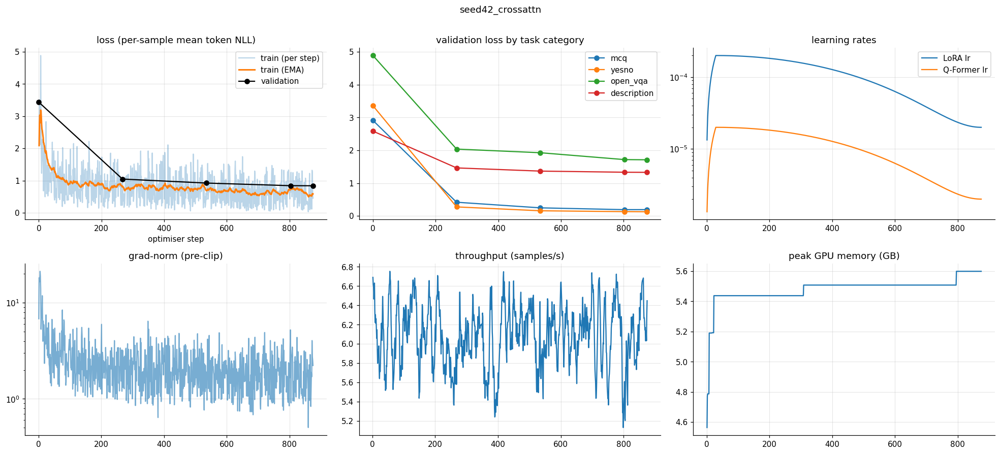

saved /kaggle/working/outputs/figs/training_curves_seed42_crossattn.png
  [finetuned] 16/1495  4s
  [finetuned] 336/1495  46s
  [finetuned] 656/1495  87s
  [finetuned] 976/1495  128s
  [finetuned] 1296/1495  170s
[finetuned] acc(mean-norm) = 0.5458 | acc(sum) = 0.5385 | 197s

==================== [seed42_crossattn] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  60s
  [finetuned_blind] 976/1495  89s
  [finetuned_blind] 1296/1495  118s
[finetuned_blind] acc(mean-norm) = 0.4254 | acc(sum) = 0.4194 | 136s
[time] [seed42_crossattn] blind control: 136.3s

==================== [seed42_crossattn] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  77s
  [probe finetuned] image 41/100  149s
  [probe finetuned] image 61/100  222s
  [probe finetuned] image 81/100  295s
[probe finetuned] done in 364s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.5785402828

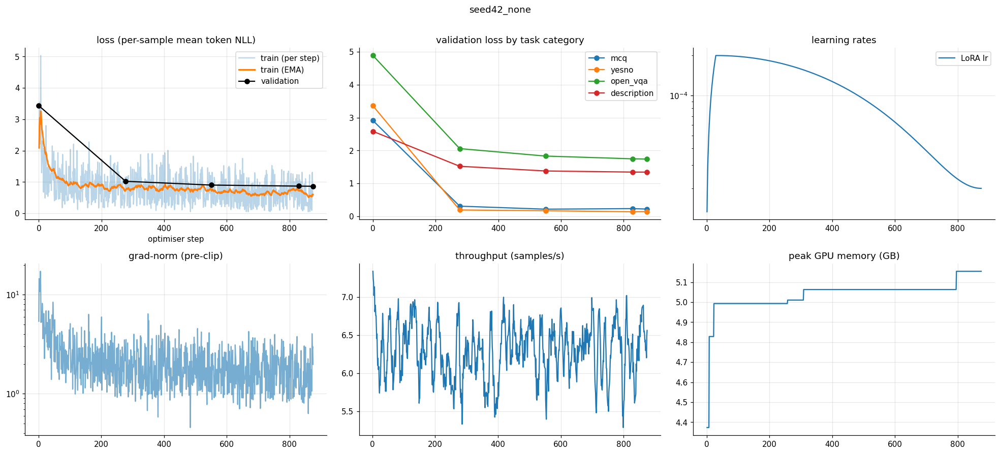

saved /kaggle/working/outputs/figs/training_curves_seed42_none.png
  [finetuned] 16/1495  4s
  [finetuned] 336/1495  46s
  [finetuned] 656/1495  87s
  [finetuned] 976/1495  129s
  [finetuned] 1296/1495  171s
[finetuned] acc(mean-norm) = 0.5191 | acc(sum) = 0.5104 | 197s

==================== [seed42_none] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  60s
  [finetuned_blind] 976/1495  89s
  [finetuned_blind] 1296/1495  117s
[finetuned_blind] acc(mean-norm) = 0.4355 | acc(sum) = 0.4201 | 136s
[time] [seed42_none] blind control: 136.2s

==================== [seed42_none] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  76s
  [probe finetuned] image 41/100  149s
  [probe finetuned] image 61/100  222s
  [probe finetuned] image 81/100  295s
[probe finetuned] done in 363s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.6017288058996201, 'proj': 0.30

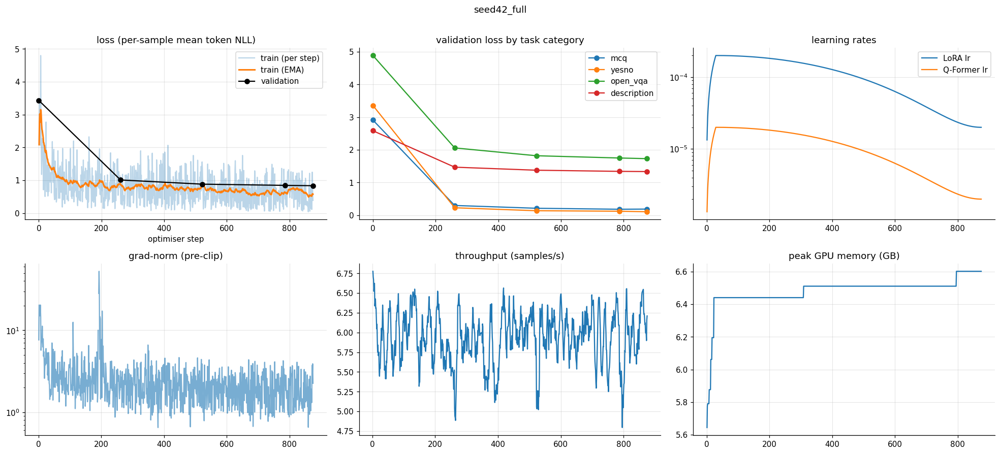

saved /kaggle/working/outputs/figs/training_curves_seed42_full.png
  [finetuned] 16/1495  3s
  [finetuned] 336/1495  46s
  [finetuned] 656/1495  86s
  [finetuned] 976/1495  128s
  [finetuned] 1296/1495  170s
[finetuned] acc(mean-norm) = 0.5485 | acc(sum) = 0.5465 | 197s

==================== [seed42_full] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  60s
  [finetuned_blind] 976/1495  89s
  [finetuned_blind] 1296/1495  118s
[finetuned_blind] acc(mean-norm) = 0.4161 | acc(sum) = 0.4140 | 136s
[time] [seed42_full] blind control: 136.5s

==================== [seed42_full] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  76s
  [probe finetuned] image 41/100  147s
  [probe finetuned] image 61/100  219s
  [probe finetuned] image 81/100  292s
[probe finetuned] done in 361s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.5260587280988693, 'proj': 0.27

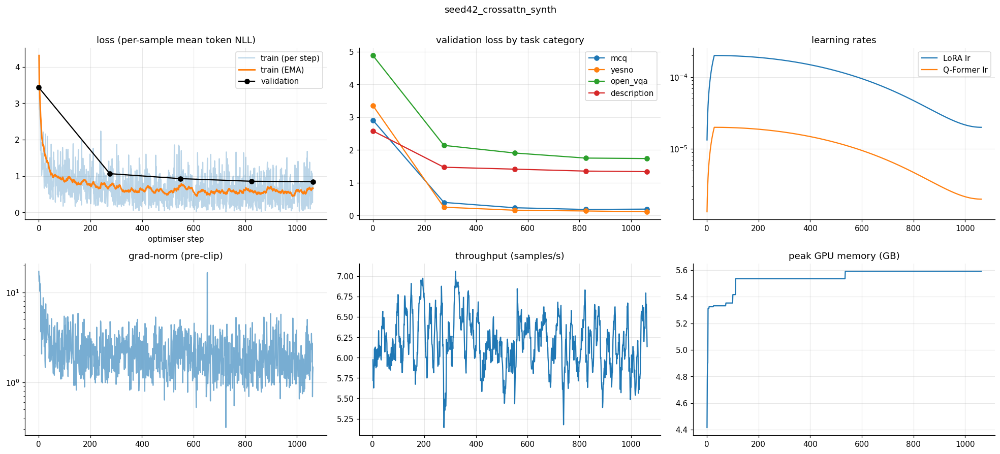

saved /kaggle/working/outputs/figs/training_curves_seed42_crossattn_synth.png
  [finetuned] 16/1495  4s
  [finetuned] 336/1495  45s
  [finetuned] 656/1495  86s
  [finetuned] 976/1495  127s
  [finetuned] 1296/1495  168s
[finetuned] acc(mean-norm) = 0.5753 | acc(sum) = 0.5786 | 195s

==================== [seed42_crossattn_synth] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  59s
  [finetuned_blind] 976/1495  88s
  [finetuned_blind] 1296/1495  116s
[finetuned_blind] acc(mean-norm) = 0.4207 | acc(sum) = 0.4140 | 134s
[time] [seed42_crossattn_synth] blind control: 134.4s

==================== [seed42_crossattn_synth] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  75s
  [probe finetuned] image 41/100  147s
  [probe finetuned] image 61/100  217s
  [probe finetuned] image 81/100  288s
[probe finetuned] done in 355s | semantic normalisers {'vit': 0.836986050605

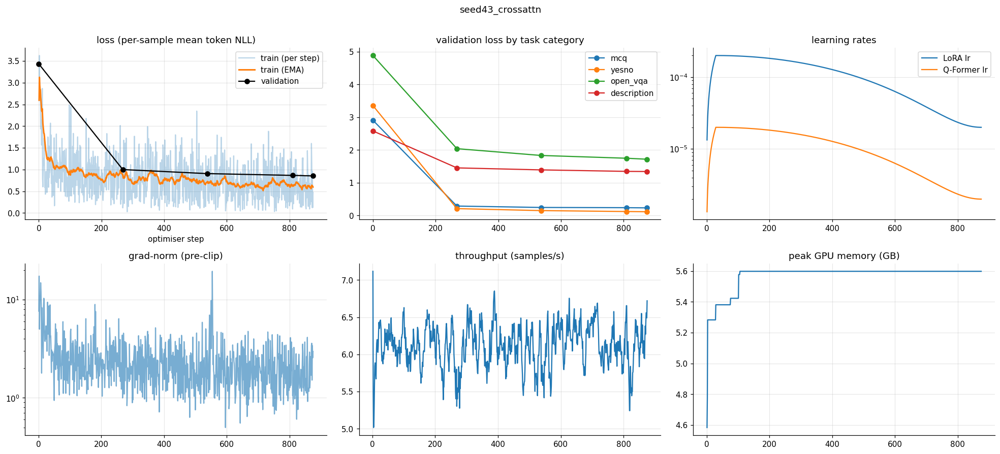

saved /kaggle/working/outputs/figs/training_curves_seed43_crossattn.png
  [finetuned] 16/1495  4s
  [finetuned] 336/1495  45s
  [finetuned] 656/1495  86s
  [finetuned] 976/1495  127s
  [finetuned] 1296/1495  168s
[finetuned] acc(mean-norm) = 0.5532 | acc(sum) = 0.5585 | 195s

==================== [seed43_crossattn] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  59s
  [finetuned_blind] 976/1495  88s
  [finetuned_blind] 1296/1495  116s
[finetuned_blind] acc(mean-norm) = 0.4174 | acc(sum) = 0.4127 | 134s
[time] [seed43_crossattn] blind control: 134.5s

==================== [seed43_crossattn] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  75s
  [probe finetuned] image 41/100  145s
  [probe finetuned] image 61/100  216s
  [probe finetuned] image 81/100  286s
[probe finetuned] done in 353s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.5720807743

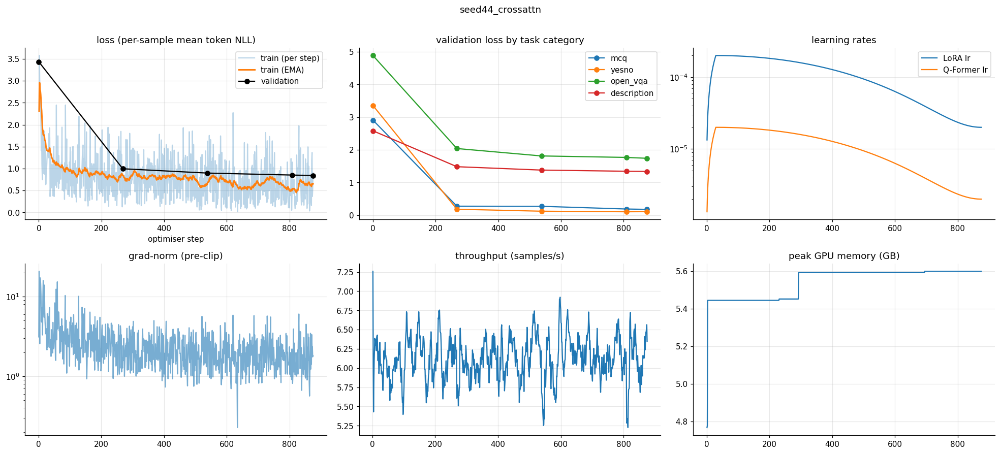

saved /kaggle/working/outputs/figs/training_curves_seed44_crossattn.png
  [finetuned] 16/1495  4s
  [finetuned] 336/1495  46s
  [finetuned] 656/1495  87s
  [finetuned] 976/1495  129s
  [finetuned] 1296/1495  171s
[finetuned] acc(mean-norm) = 0.5612 | acc(sum) = 0.5645 | 198s

==================== [seed44_crossattn] blind control ====================
  [finetuned_blind] 16/1495  3s
  [finetuned_blind] 336/1495  32s
  [finetuned_blind] 656/1495  60s
  [finetuned_blind] 976/1495  89s
  [finetuned_blind] 1296/1495  117s
[finetuned_blind] acc(mean-norm) = 0.4328 | acc(sum) = 0.4194 | 136s
[time] [seed44_crossattn] blind control: 136.3s

==================== [seed44_crossattn] probing ====================
  [probe finetuned] image 1/100  4s
  [probe finetuned] image 21/100  77s
  [probe finetuned] image 41/100  150s
  [probe finetuned] image 61/100  223s
  [probe finetuned] image 81/100  295s
[probe finetuned] done in 365s | semantic normalisers {'vit': 0.8369860506057739, 'qf': 0.5022106283

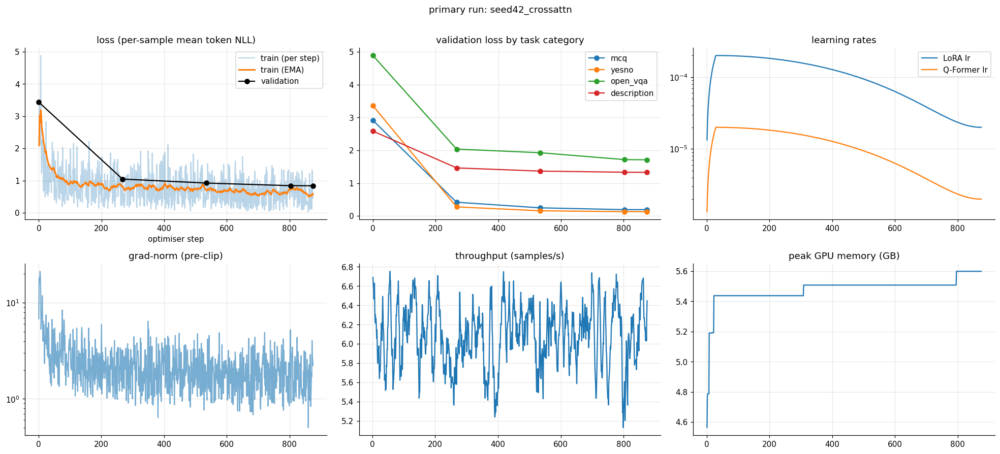

saved /kaggle/working/outputs/figs/training_curves.png
[time] Training curves (primary run): 2.0s
primary run for the detailed analysis: seed42_crossattn


In [18]:
# ---------------------------------------------------------------- 6.1 Run ALL experiments (train -> evaluate -> probe -> save), one after another
RUNS_V0 = {}              # val loss of the first experiment before training (reset sanity check)
RUNS = {}                 # name -> dict(exp, results, ft_df, ft_blind_df, probe, gen, hist, val_hist)
SKIPPED = []
EXP_MINUTES = []
RUNS_DIR = os.path.join(OUT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

def estimate_minutes(exp):
    base = max(EXP_MINUTES) if EXP_MINUTES else (12.0 if SMOKE_TEST else 70.0)
    return base * (1.3 if exp["synth"] else 1.0)

for exp in EXPERIMENTS:
    elapsed = (time.time() - T0_NOTEBOOK) / 60
    left = TIME_LIMIT_HOURS * 60 - elapsed - 15.0                  # keep 15 min for the final analysis
    if estimate_minutes(exp) > left:
        print(f"[SKIP] {exp['name']}: needs ~{estimate_minutes(exp):.0f} min, only {left:.0f} min left before the safety limit")
        SKIPPED.append(exp["name"])
        continue
    t_exp = time.time()
    run_dir = os.path.join(RUNS_DIR, exp["name"])
    os.makedirs(run_dir, exist_ok=True)
    print(f"\n{'#' * 30} EXPERIMENT {exp['name']} ({len(RUNS) + 1}/{len(EXPERIMENTS)}) | notebook time {elapsed:.0f} min {'#' * 30}")
    try:
        lora, qf, proj, setup = setup_experiment(exp)
        recs = train_recs + (SYNTH_RECS if exp["synth"] else [])
        hist, val_hist, info = train_one(exp, recs, lora, qf, proj)
        del lora, qf, proj
        if abs(info["val_before"]["val_loss"] - RUNS_V0.setdefault("v0", info["val_before"]["val_loss"])) > 0.02:
            print(f"[WARN] val loss before training differs from the first experiment "
                  f"({info['val_before']['val_loss']:.4f} vs {RUNS_V0['v0']:.4f}) -> the reset may be incomplete")
        pd.DataFrame(hist).to_csv(os.path.join(run_dir, "train_history.csv"), index=False)
        pd.DataFrame(val_hist).to_csv(os.path.join(run_dir, "val_history.csv"), index=False)
        torch.save({n: p.detach().half().cpu() for n, p in model.named_parameters() if p.requires_grad},
                   os.path.join(run_dir, "trainable_weights.pt"))
        plot_training(hist, val_hist, f"training_curves_{exp['name']}", title=exp["name"])

        ft = eval_qbench("finetuned", out_dir=run_dir)
        ft_blind = None
        with section(f"[{exp['name']}] blind control"):
            ft_blind = eval_qbench("finetuned_blind", blind=True, out_dir=run_dir)
        probe = None
        with section(f"[{exp['name']}] probing"):
            probe = run_probe("finetuned")
            probe[0].to_csv(os.path.join(run_dir, "probe_sensitivity_finetuned.csv"), index=False)
            probe[3].to_csv(os.path.join(run_dir, "probe_psychometric_finetuned.csv"), index=False)
        gen = None
        with section(f"[{exp['name']}] generations"):
            gen = run_generations("finetuned")
            gen.to_csv(os.path.join(run_dir, "generations.csv"), index=False)
            for r in gen.itertuples():
                print(f"[{r.kind} {r.ref} {r.prompt}] {r.text}")
        res = {"run_name": exp["name"], "experiment": exp,
               "config": {**CFG, "seed": exp["seed"], "train_qformer": exp["train_qformer"], "add_synth": exp["synth"]},
               "training_setup": setup, "training": info}
        with section(f"[{exp['name']}] metrics"):
            res.update(run_metrics(ft, ft_blind, probe))
        res["experiment_minutes"] = (time.time() - t_exp) / 60
        with open(os.path.join(run_dir, f"results_summary_{exp['name']}.json"), "w") as f:
            json.dump(res, f, indent=2, default=_json_default)
        RUNS[exp["name"]] = dict(exp=exp, results=res, ft_df=ft, ft_blind_df=ft_blind, probe=probe, gen=gen, hist=hist, val_hist=val_hist)
        q = res["qbench_finetuned"]
        print(f"[{exp['name']}] DONE in {res['experiment_minutes']:.1f} min | Q-Bench {100 * q['overall']:.2f}% "
              f"(Y/N {100 * q.get('qtype:Yes/No', np.nan):.1f}, What {100 * q.get('qtype:What', np.nan):.1f}, How {100 * q.get('qtype:How', np.nan):.1f})")
    except Exception as e:
        FAILED_SECTIONS.append((f"experiment {exp['name']}", repr(e)))
        print(f"[ERROR] experiment {exp['name']} failed: {e!r} -> continuing with the next experiment")
        traceback.print_exc()
    finally:
        EXP_MINUTES.append((time.time() - t_exp) / 60)
        model.eval()
        plt.close("all"); gc.collect(); torch.cuda.empty_cache()
    RESULTS["experiments_done"] = list(RUNS); RESULTS["experiments_skipped"] = SKIPPED
    save_results()

print("\nfinished experiments:", list(RUNS), "| skipped:", SKIPPED, "| failed:", [f for f in FAILED_SECTIONS if f[0].startswith("experiment")])
assert RUNS, "no experiment finished — see the errors above"

# the PRIMARY run (first finished one, normally seed42_crossattn) feeds the detailed single-run analysis in section 7
PRIMARY = EXPERIMENTS[0]["name"] if EXPERIMENTS[0]["name"] in RUNS else next(iter(RUNS))
P_ = RUNS[PRIMARY]
ft_df, ft_blind_df, probe_ft, gen_ft = P_["ft_df"], P_["ft_blind_df"], P_["probe"], P_["gen"]
HIST, VAL_HIST = P_["hist"], P_["val_hist"]
RESULTS["primary_run"] = PRIMARY
RESULTS["training_setup"], RESULTS["training"] = P_["results"]["training_setup"], P_["results"]["training"]
for k in ("qbench_finetuned", "qbench_finetuned_sumrule", "qbench_finetuned_blind"):
    if k in P_["results"]:
        RESULTS[k] = P_["results"][k]
for name in ("train_history.csv", "val_history.csv"):
    shutil.copy(os.path.join(RUNS_DIR, PRIMARY, name), os.path.join(OUT_DIR, name))
for name in glob.glob(os.path.join(RUNS_DIR, PRIMARY, "qbench_preds_*.csv")):
    shutil.copy(name, os.path.join(OUT_DIR, os.path.basename(name)))
if gen_ft is not None:
    pd.concat([g for g in (gen_zs, gen_ft) if g is not None]).to_csv(os.path.join(OUT_DIR, "generations.csv"), index=False)
with section("Training curves (primary run)"):
    plot_training(HIST, VAL_HIST, "training_curves", title=f"primary run: {PRIMARY}")
save_results()
print("primary run for the detailed analysis:", PRIMARY)


==================== Aggregate tables ====================
per run (accuracies in %):
                   run                              setting  seed  overall  yesno  what   how  blind  visual_reliance  yes_rate  val_loss  train_min  trainable_M  probe6  probe21  ret_noise  ret_blur  ret_jpeg  ret_oversmooth  ret_ringing  det_noise  det_blur  det_jpeg  det_oversmooth  det_ringing
           seed42_none          LoRA only (Q-Former frozen)    42    51.91  61.09 45.80 47.26  43.55             8.36     52.91     0.861     39.037       23.593   84.38    55.67      1.029     0.743     0.841           0.751        0.733      0.110     0.295     0.071           0.176        0.010
      seed42_crossattn LoRA + Q-Former cross-attn (default)    42    54.58  68.55 43.58 49.09  42.54            12.04     57.82     0.838     40.270       45.668   89.57    63.24      1.236     0.759     0.689           0.801        0.648      0.220     0.718     0.348           0.386        0.100
      seed43_cro

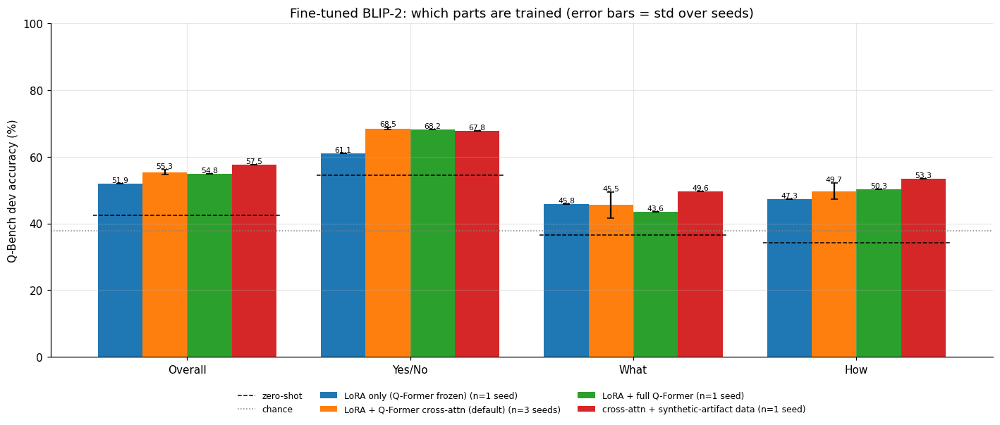

saved /kaggle/working/outputs/figs/agg_qbench_by_setting.png
[time] Figure: Q-Bench accuracy by setting: 0.6s

==================== Figure: bottleneck metrics by setting ====================


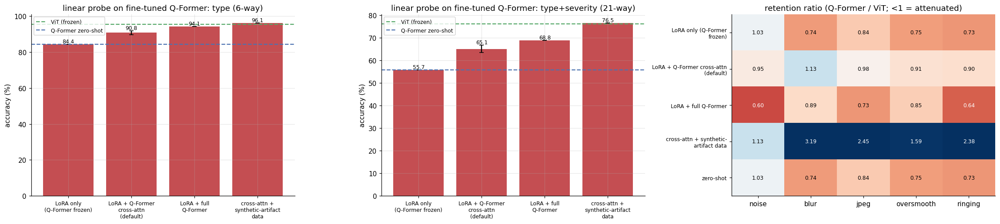

saved /kaggle/working/outputs/figs/agg_bottleneck_by_setting.png
[time] Figure: bottleneck metrics by setting: 1.2s

==================== Figure: distortion detection by setting ====================


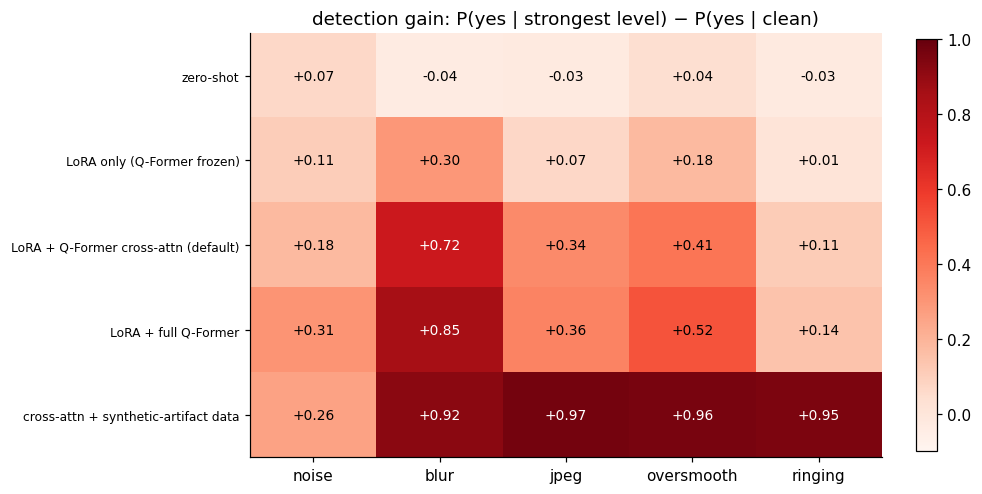

saved /kaggle/working/outputs/figs/agg_detection_by_setting.png
[time] Figure: distortion detection by setting: 0.5s

==================== Figure: validation curves of all runs ====================


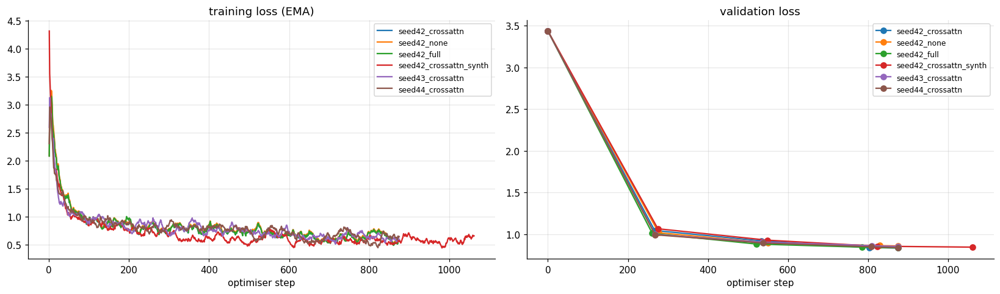

saved /kaggle/working/outputs/figs/agg_training_curves.png
[time] Figure: validation curves of all runs: 0.8s


In [19]:
# ---------------------------------------------------------------- 6.2 Aggregate all experiments: seeds (mean ± std) and ablations
SETTING_LABEL = {("none", False): "LoRA only (Q-Former frozen)", ("crossattn", False): "LoRA + Q-Former cross-attn (default)",
                 ("full", False): "LoRA + full Q-Former", ("crossattn", True): "cross-attn + synthetic-artifact data",
                 ("none", True): "LoRA only + synthetic data", ("full", True): "full Q-Former + synthetic data"}
SETTING_ORDER = list(SETTING_LABEL.values())

def setting_of(exp):
    return SETTING_LABEL[(exp["train_qformer"], exp["synth"])]

def run_row(name, R):
    res = R["results"]
    q, qb_ = res.get("qbench_finetuned", {}), res.get("qbench_finetuned_blind", {})
    nan = float("nan")
    row = dict(run=name, setting=setting_of(R["exp"]), seed=R["exp"]["seed"],
               overall=q.get("overall", nan), yesno=q.get("qtype:Yes/No", nan), what=q.get("qtype:What", nan), how=q.get("qtype:How", nan),
               blind=qb_.get("overall", nan), visual_reliance=res.get("visual_reliance", {}).get("finetuned", nan),
               yes_rate=res.get("yes_rate", {}).get("finetuned", nan),
               val_loss=res["training"]["val_after"]["val_loss"], train_min=res["training"]["minutes"],
               trainable_M=res["training_setup"]["trainable_M"])
    for p in res.get("linear_probes", []):
        if p["space"] == "Q-Former fine-tuned":
            row["probe6" if p["task"].startswith("type (") else "probe21"] = p["acc"]
    for d, v in res.get("sensitivity_retention", {}).get("Q-Former output, fine-tuned", {}).items():
        row[f"ret_{d}"] = v
    for p in res.get("psychometric", []):
        if p["model"] == "finetuned":
            row[f"det_{p['dist']}"] = p["detect_gain"]
    return row

AGG = {}
with section("Aggregate tables"):
    per_run = pd.DataFrame([run_row(n, R) for n, R in RUNS.items()])
    per_run["setting"] = pd.Categorical(per_run.setting, categories=SETTING_ORDER, ordered=True)
    per_run = per_run.sort_values(["setting", "seed"]).reset_index(drop=True)
    per_run.to_csv(os.path.join(OUT_DIR, "aggregate_per_run.csv"), index=False)
    num_cols = [c for c in per_run.columns if c not in ("run", "setting", "seed")]
    g = per_run.groupby("setting", observed=True)[num_cols]
    by_setting = g.mean().add_suffix("_mean").join(g.std(ddof=1).add_suffix("_std")).join(g.size().rename("n_runs"))
    by_setting.to_csv(os.path.join(OUT_DIR, "aggregate_by_setting.csv"))
    print("per run (accuracies in %):")
    show = per_run.copy()
    for c in ["overall", "yesno", "what", "how", "blind", "visual_reliance", "yes_rate", "probe6", "probe21"]:
        if c in show:
            show[c] = (100 * show[c]).round(2)
    print(show.round(3).to_string(index=False))
    # paired McNemar of every run against the primary run (same 1,495 questions)
    sig = []
    for n, R in RUNS.items():
        if n == PRIMARY:
            continue
        a, b = RUNS[PRIMARY]["ft_df"].correct.values, R["ft_df"].correct.values
        n01, n10, p = mcnemar(a, b)
        dlo, dhi = bootstrap_ci(b.astype(float) - a.astype(float))
        sig.append(dict(run=n, vs=PRIMARY, delta=float(b.mean() - a.mean()), delta_ci=[dlo, dhi], fixed=n01, broken=n10, mcnemar_p=p))
    sig = pd.DataFrame(sig)
    if len(sig):
        print("\npaired comparison with the primary run (delta in pts):")
        print(sig.assign(delta=100 * sig.delta).round(4).to_string(index=False))
    AGG = dict(per_run=per_run.astype(object).where(per_run.notna(), None).to_dict("records"),
               by_setting={str(k): {kk: (None if pd.isna(vv) else float(vv)) for kk, vv in v.items()} for k, v in by_setting.iterrows()},
               vs_primary=sig.to_dict("records") if len(sig) else [],
               zero_shot=dict(overall=RESULTS["qbench_zeroshot"]["overall"], linear_probes=ZS_REF["linear_probes"],
                              retention=ZS_REF["retention"], psychometric=ZS_REF["psychometric"]))
    RESULTS["aggregate"] = AGG
    save_results()

def _ms(s):
    s = pd.Series(s).dropna().astype(float)
    return (s.mean(), s.std(ddof=1) if len(s) > 1 else 0.0) if len(s) else (np.nan, 0.0)

with section("Figure: Q-Bench accuracy by setting"):
    cols = [("overall", "Overall"), ("yesno", "Yes/No"), ("what", "What"), ("how", "How")]
    settings = [s for s in SETTING_ORDER if s in set(per_run.setting.astype(str))]
    fig, ax = plt.subplots(figsize=(13, 5.6))
    w = 0.8 / max(1, len(settings))
    for i, s in enumerate(settings):
        sub = per_run[per_run.setting.astype(str) == s]
        ms = [_ms(100 * sub[c]) for c, _ in cols]
        n = len(sub)
        bars = ax.bar(np.arange(len(cols)) + i * w - 0.4 + w / 2, [m for m, _ in ms], w, yerr=[sd for _, sd in ms], capsize=3,
                      label=f"{s} (n={n} seed{'s' if n > 1 else ''})")
        ax.bar_label(bars, fmt="%.1f", fontsize=7)
    zs_vals = [100 * RESULTS["qbench_zeroshot"].get(k, np.nan) for k in ("overall", "qtype:Yes/No", "qtype:What", "qtype:How")]
    for j, v in enumerate(zs_vals):
        ax.hlines(v, j - 0.42, j + 0.42, colors="k", linestyles="--", lw=1, label="zero-shot" if j == 0 else None)
    ax.axhline(100 * CHANCE, color="gray", ls=":", lw=1, label="chance")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([c for _, c in cols]); ax.set_ylabel("Q-Bench dev accuracy (%)"); ax.set_ylim(0, 100)
    ax.set_title("Fine-tuned BLIP-2: which parts are trained (error bars = std over seeds)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
    savefig("agg_qbench_by_setting")

with section("Figure: bottleneck metrics by setting"):
    settings = [s for s in SETTING_ORDER if s in set(per_run.setting.astype(str))]
    fig, ax = plt.subplots(1, 3, figsize=(21, 4.8))
    zs_p = {(p["space"], p["task"]): p["acc"] for p in ZS_REF["linear_probes"]}
    for j, (col, task) in enumerate([("probe6", "type (6-way)"), ("probe21", "type+severity (21-way)")]):
        ms = [_ms(100 * per_run[per_run.setting.astype(str) == s][col]) if col in per_run else (np.nan, 0) for s in settings]
        bars = ax[j].bar(range(len(settings)), [m for m, _ in ms], yerr=[sd for _, sd in ms], capsize=3, color="#C44E52")
        ax[j].bar_label(bars, fmt="%.1f", fontsize=8)
        for space, c in [("ViT (frozen)", "#55A868"), ("Q-Former zero-shot", "#4C72B0")]:
            if (space, task) in zs_p:
                ax[j].axhline(100 * zs_p[(space, task)], color=c, ls="--", label=space)
        ax[j].set_xticks(range(len(settings))); ax[j].set_xticklabels([wrap(s, 18) for s in settings], fontsize=8)
        ax[j].set_title(f"linear probe on fine-tuned Q-Former: {task}"); ax[j].set_ylabel("accuracy (%)"); ax[j].legend(fontsize=8)
    ret_cols = [f"ret_{d}" for d in DIST_NAMES]
    M = np.array([[_ms(per_run[per_run.setting.astype(str) == s][c])[0] if c in per_run else np.nan for c in ret_cols] for s in settings]
                 + [[ZS_REF["retention"].get(d, np.nan) for d in DIST_NAMES]])
    ax[2].imshow(M, cmap="RdBu", vmin=0.4, vmax=1.6, aspect="auto")
    ax[2].set_xticks(range(len(DIST_NAMES))); ax[2].set_xticklabels(DIST_NAMES)
    ax[2].set_yticks(range(len(settings) + 1)); ax[2].set_yticklabels([wrap(s, 26) for s in settings] + ["zero-shot"], fontsize=8)
    for i in range(M.shape[0]):
        for k in range(M.shape[1]):
            ax[2].text(k, i, f"{M[i, k]:.2f}", ha="center", va="center", fontsize=8,
                       color="white" if np.isfinite(M[i, k]) and abs(M[i, k] - 1.0) > 0.35 else "black")
    ax[2].set_title("retention ratio (Q-Former / ViT; <1 = attenuated)"); ax[2].grid(False)
    savefig("agg_bottleneck_by_setting")

with section("Figure: distortion detection by setting"):
    settings = [s for s in SETTING_ORDER if s in set(per_run.setting.astype(str))]
    det_cols = [f"det_{d}" for d in DIST_NAMES]
    zs_det = {p["dist"]: p["detect_gain"] for p in ZS_REF["psychometric"]}
    M = np.array([[zs_det.get(d, np.nan) for d in DIST_NAMES]] +
                 [[_ms(per_run[per_run.setting.astype(str) == s][c])[0] if c in per_run else np.nan for c in det_cols] for s in settings])
    plt.figure(figsize=(9, 0.6 * M.shape[0] + 1.6))
    plt.imshow(M, cmap="Reds", vmin=-0.1, vmax=1.0, aspect="auto")
    plt.xticks(range(len(DIST_NAMES)), DIST_NAMES); plt.yticks(range(M.shape[0]), ["zero-shot"] + settings, fontsize=8)
    for i in range(M.shape[0]):
        for k in range(M.shape[1]):
            plt.text(k, i, f"{M[i, k]:+.2f}", ha="center", va="center", fontsize=9,
                     color="white" if np.isfinite(M[i, k]) and M[i, k] > 0.6 else "black")
    plt.title("detection gain: P(yes | strongest level) − P(yes | clean)"); plt.grid(False); plt.colorbar(fraction=0.03)
    savefig("agg_detection_by_setting")

with section("Figure: validation curves of all runs"):
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for n, R in RUNS.items():
        h, vh = pd.DataFrame(R["hist"]), pd.DataFrame(R["val_hist"])
        if len(h):
            ax[0].plot(h.step, h.loss.ewm(alpha=0.05).mean(), label=n)
        if len(vh):
            ax[1].plot(vh.step, vh.val_loss, "o-", label=n)
    ax[0].set_title("training loss (EMA)"); ax[1].set_title("validation loss")
    for a in ax:
        a.set_xlabel("optimiser step"); a.legend(fontsize=8)
    savefig("agg_training_curves")

detailed analysis of the primary run: seed42_crossattn

==================== Q-Bench results table ====================
                  Overall Overall (sum rule)    How   What Yes/No Global distortion Global other Local distortion Local other          95% CI
Zero-shot           42.41              41.94  34.28   36.5  54.55             38.72        44.68            41.45       47.35  [0.399, 0.448]
Fine-tuned (ours)   54.58              53.85  49.09  43.58  68.55             52.33        56.02            53.29       58.37  [0.522, 0.571]
Zero-shot, blind    39.87              38.53  31.44  30.53  55.09             39.11        40.97            40.79       38.37  [0.375, 0.423]
Fine-tuned, blind   42.54              41.94  41.78  33.63  50.55             42.41        42.13            39.47       47.35  [0.400, 0.451]
Chance               37.8                                                                                                                    

FT - ZS = +12.17 pts, 95% C

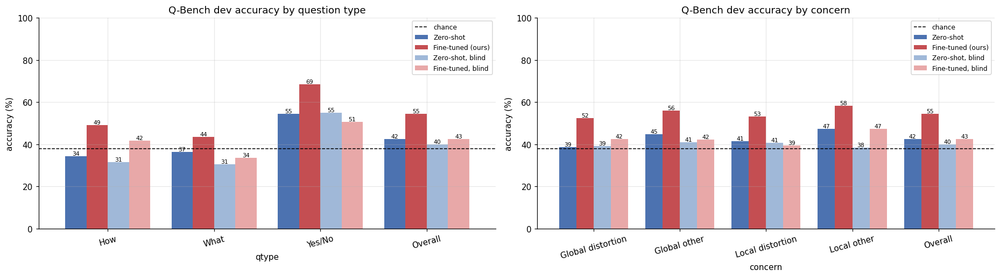

saved /kaggle/working/outputs/figs/qbench_accuracy_breakdown.png
[time] Figure: accuracy by type / concern: 1.2s

==================== Figure: type x concern heatmaps ====================


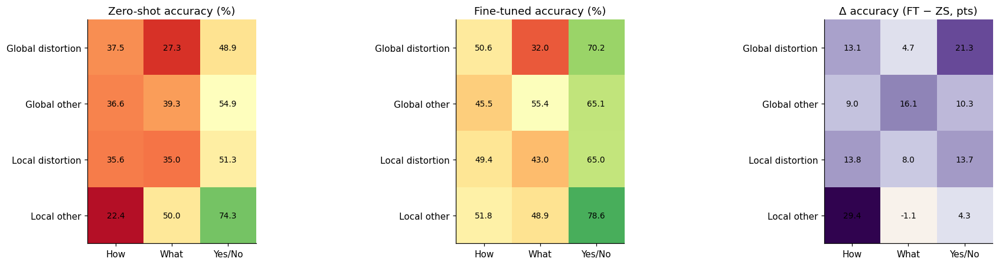

saved /kaggle/working/outputs/figs/qbench_type_concern_heatmap.png
[time] Figure: type x concern heatmaps: 0.6s


In [20]:
# ---------------------------------------------------------------- 7.1 Primary run: Q-Bench tables, bootstrap CIs, McNemar
print("detailed analysis of the primary run:", PRIMARY)
runs = {"Zero-shot": zs_df, "Fine-tuned (ours)": ft_df}
if zs_blind_df is not None:
    runs["Zero-shot, blind"] = zs_blind_df
if ft_blind_df is not None:
    runs["Fine-tuned, blind"] = ft_blind_df

with section("Q-Bench results table"):
    tab = {}
    for name, d in runs.items():
        row = {"Overall": d.correct.mean(), "Overall (sum rule)": d.correct_sum.mean()}
        row.update({f"{g}": v for g, v in d.groupby("qtype").correct.mean().items()})
        row.update({f"{g}": v for g, v in d.groupby("concern").correct.mean().items()})
        lo, hi = bootstrap_ci(d.correct)
        row["95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
        tab[name] = row
    tab["Chance"] = {"Overall": CHANCE}
    table = pd.DataFrame(tab).T
    print((table.drop(columns=["95% CI"]).astype(float) * 100).round(2).astype(str).replace("nan", "")
          .join(table["95% CI"].fillna("")).to_string())
    table.to_csv(os.path.join(OUT_DIR, "qbench_results_table.csv"))
    n01, n10, p = mcnemar(zs_df.correct.values, ft_df.correct.values)
    diff = ft_df.correct.values.astype(float) - zs_df.correct.values.astype(float)
    dlo, dhi = bootstrap_ci(diff)
    print(f"\nFT - ZS = {100 * diff.mean():+.2f} pts, 95% CI [{100 * dlo:+.2f}, {100 * dhi:+.2f}] | McNemar: fixed {n01}, broken {n10}, p = {p:.2e}")
    RESULTS["significance"] = dict(delta=float(diff.mean()), delta_ci=[dlo, dhi], fixed=n01, broken=n10, mcnemar_p=p)
    if qb.near_dup.any():
        m = ~qb.near_dup.values
        RESULTS["qbench_no_near_dups"] = dict(zeroshot=float(zs_df.correct[m].mean()), finetuned=float(ft_df.correct[m].mean()), n=int(m.sum()))
        print("excluding near-duplicates of training images:", RESULTS["qbench_no_near_dups"])
    # visual reliance: how much of the accuracy needs the image?
    if zs_blind_df is not None and ft_blind_df is not None:
        RESULTS["visual_reliance"] = dict(zeroshot=float(zs_df.correct.mean() - zs_blind_df.correct.mean()),
                                          finetuned=float(ft_df.correct.mean() - ft_blind_df.correct.mean()))
        print("visual reliance (acc(real image) - acc(gray image)):", {k: round(100 * v, 2) for k, v in RESULTS["visual_reliance"].items()})
    save_results()

with section("Figure: accuracy by type / concern"):
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
    for a, key in zip(ax, ["qtype", "concern"]):
        parts = []
        for name, d in runs.items():
            s = d.groupby(key).correct.mean(); s["Overall"] = d.correct.mean(); parts.append(s.rename(name))
        dd = pd.concat(parts, axis=1) * 100
        dd.plot.bar(ax=a, width=0.8, color=["#4C72B0", "#C44E52", "#A0B8D8", "#E8A8A8"][:dd.shape[1]])
        a.axhline(100 * CHANCE, ls="--", color="k", lw=1, label="chance"); a.set_ylabel("accuracy (%)"); a.set_ylim(0, 100)
        a.set_title(f"Q-Bench dev accuracy by {'question type' if key == 'qtype' else 'concern'}"); a.tick_params(axis="x", rotation=15)
        for cont in a.containers:
            a.bar_label(cont, fmt="%.0f", fontsize=7)
        a.legend(fontsize=8)
    savefig("qbench_accuracy_breakdown")

with section("Figure: type x concern heatmaps"):
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
    mats = {}
    for a, (name, d) in zip(ax, [("Zero-shot", zs_df), ("Fine-tuned", ft_df)]):
        mats[name] = d.pivot_table(index="concern", columns="qtype", values="correct", aggfunc="mean") * 100
        a.imshow(mats[name].values, cmap="RdYlGn", vmin=20, vmax=90)
        a.set_title(f"{name} accuracy (%)")
    mats["Δ (FT − ZS)"] = mats["Fine-tuned"] - mats["Zero-shot"]
    ax[2].imshow(mats["Δ (FT − ZS)"].values, cmap="PuOr", vmin=-30, vmax=30); ax[2].set_title("Δ accuracy (FT − ZS, pts)")
    for a, (name, M) in zip(ax, mats.items()):
        a.set_xticks(range(M.shape[1])); a.set_xticklabels(M.columns); a.set_yticks(range(M.shape[0])); a.set_yticklabels(M.index); a.grid(False)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                a.text(j, i, f"{M.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
    savefig("qbench_type_concern_heatmap")


==================== Yes/No bias ====================
                   pred_yes_rate  gt_yes_rate  acc_on_gt_yes  acc_on_gt_no
model                                                                     
Zero-shot                   83.8         57.1           84.1          16.5
Fine-tuned (ours)           57.8         57.1           73.6          63.1
Zero-shot, blind            82.0         57.1           82.8          19.1
Fine-tuned, blind           42.4         57.1           44.3          60.2


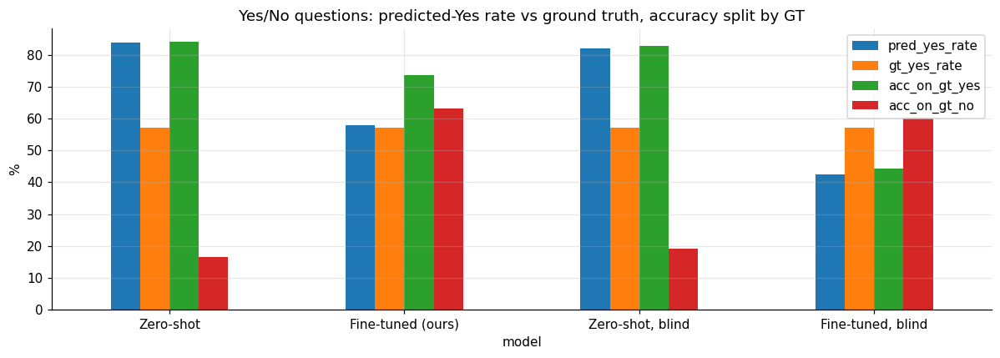

saved /kaggle/working/outputs/figs/qbench_yes_bias.png
[time] Yes/No bias: 0.4s

==================== Position bias ====================


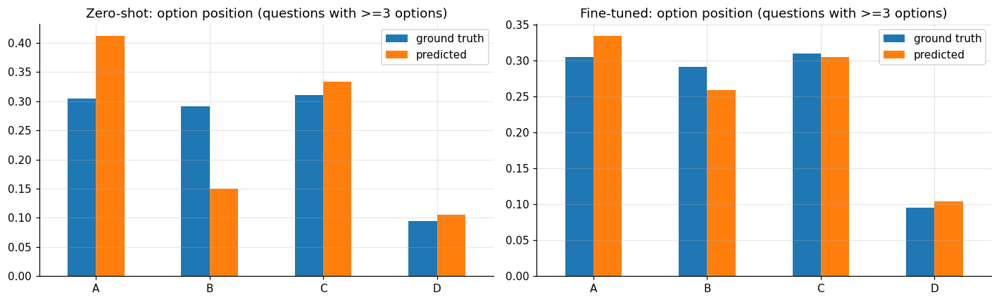

saved /kaggle/working/outputs/figs/qbench_position_bias.png
[time] Position bias: 0.6s

==================== Calibration ====================


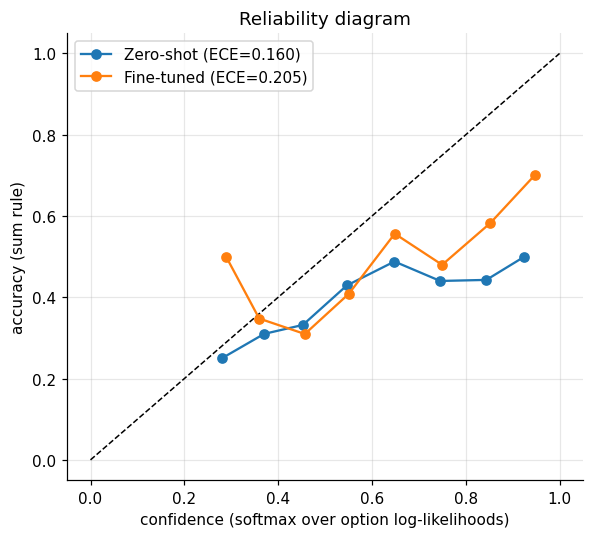

saved /kaggle/working/outputs/figs/qbench_calibration.png
[time] Calibration: 0.3s

==================== Accuracy by distortion keyword ====================
                            n  zeroshot  finetuned  delta
group                                                    
compression / artifacts    10      60.0       40.0  -20.0
texture / detail           27      33.3       63.0   29.6
noise / grain              40      47.5       67.5   20.0
composition               127      60.6       65.4    4.7
color                     242      45.9       52.5    6.6
exposure / lighting       264      41.3       56.1   14.8
blur / focus / sharpness  519      41.6       56.6   15.0


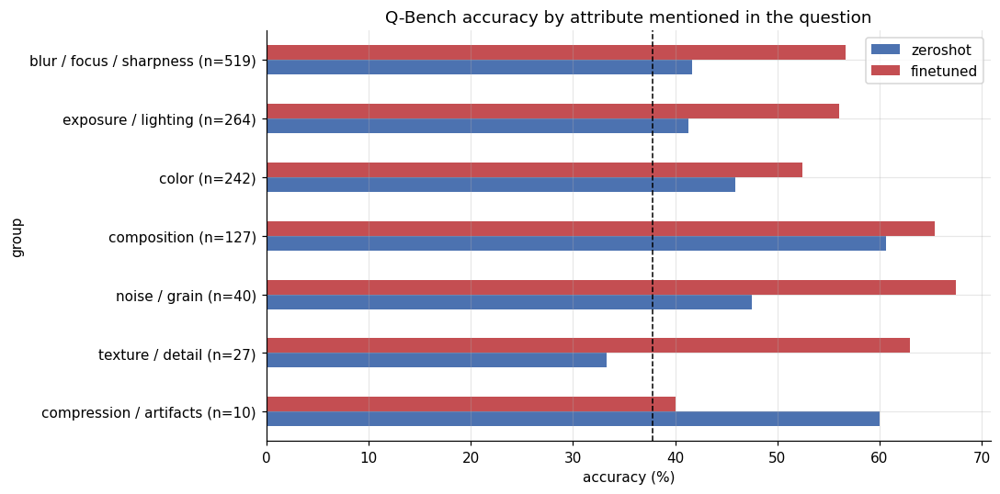

saved /kaggle/working/outputs/figs/qbench_keyword_groups.png
[time] Accuracy by distortion keyword: 0.4s

==================== Qualitative examples ====================


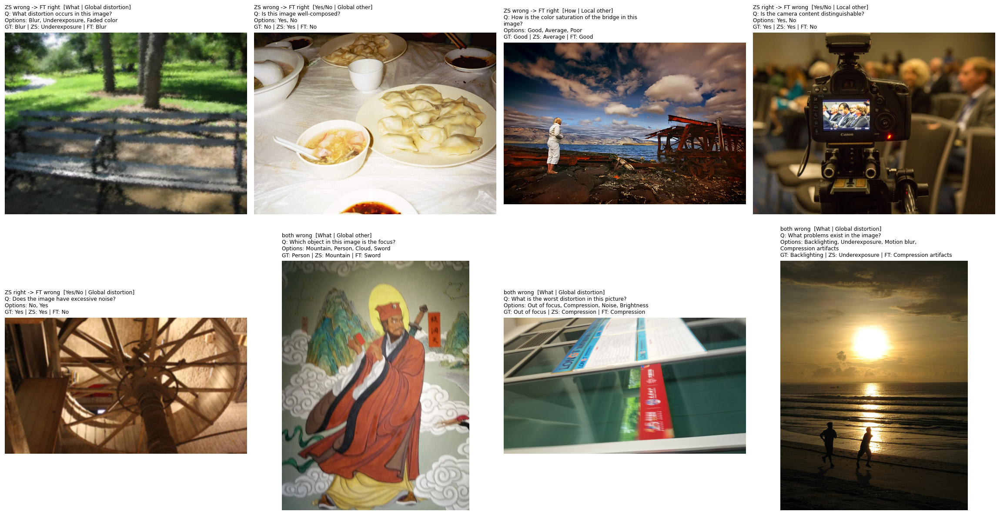

saved /kaggle/working/outputs/figs/qbench_qualitative_examples.png


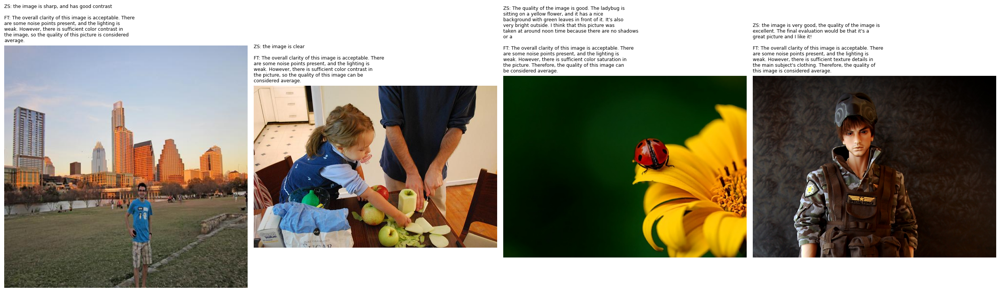

saved /kaggle/working/outputs/figs/generations_qbench_descriptions.png
[time] Qualitative examples: 8.7s


In [21]:
# ---------------------------------------------------------------- 7.2 Error analysis: yes-bias, position bias, calibration, distortion keywords, examples
with section("Yes/No bias"):
    rows_ = []
    for name, d in runs.items():
        yn = d[d.qtype == "Yes/No"]
        if len(yn) == 0:
            continue
        pred_yes = np.array([o[p] == "Yes" for o, p in zip(yn.options, yn.pred_mean)])
        gt_yes = np.array([o[g] == "Yes" for o, g in zip(yn.options, yn.gt_idx)])
        rows_.append(dict(model=name, pred_yes_rate=pred_yes.mean(), gt_yes_rate=gt_yes.mean(),
                          acc_on_gt_yes=float((pred_yes == gt_yes)[gt_yes].mean()) if gt_yes.any() else np.nan,
                          acc_on_gt_no=float((pred_yes == gt_yes)[~gt_yes].mean()) if (~gt_yes).any() else np.nan))
    yb = pd.DataFrame(rows_).set_index("model")
    print((yb * 100).round(1))
    RESULTS["yes_bias"] = yb.round(4).to_dict("index")
    (yb[["pred_yes_rate", "gt_yes_rate", "acc_on_gt_yes", "acc_on_gt_no"]] * 100).plot.bar(figsize=(11, 4), rot=0)
    plt.title("Yes/No questions: predicted-Yes rate vs ground truth, accuracy split by GT"); plt.ylabel("%")
    savefig("qbench_yes_bias")

with section("Position bias"):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for a, (name, d) in zip(ax, [("Zero-shot", zs_df), ("Fine-tuned", ft_df)]):
        sub = d[d.n_opts >= 3]
        pd.DataFrame({"ground truth": sub.gt_idx.value_counts(normalize=True), "predicted": sub.pred_mean.value_counts(normalize=True)}) \
            .sort_index().rename(index=lambda i: "ABCD"[i]).plot.bar(ax=a, rot=0)
        a.set_title(f"{name}: option position (questions with >=3 options)")
    savefig("qbench_position_bias")

with section("Calibration"):
    plt.figure(figsize=(5.5, 5))
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    RESULTS["ece"] = {}
    for name, d in [("Zero-shot", zs_df), ("Fine-tuned", ft_df)]:
        e, xs, ys, ns = ece(d.conf, d.correct_sum)
        RESULTS["ece"][name] = e
        plt.plot(xs, ys, "o-", label=f"{name} (ECE={e:.3f})")
    plt.xlabel("confidence (softmax over option log-likelihoods)"); plt.ylabel("accuracy (sum rule)"); plt.legend(); plt.title("Reliability diagram")
    savefig("qbench_calibration")

KW_GROUPS = {
    "blur / focus / sharpness": r"blur|focus|sharp|clarity|clear",
    "noise / grain": r"nois|grain",
    "exposure / lighting": r"expos|bright|dark|light|illumin",
    "color": r"colou?r|saturat|vivid|tone",
    "texture / detail": r"textur|detail",
    "compression / artifacts": r"compress|jpeg|artifact|block|pixel",
    "composition": r"compos|center|framing",
}
with section("Accuracy by distortion keyword"):
    rows_ = []
    for g, pat in KW_GROUPS.items():
        m = zs_df.question.str.lower().str.contains(pat).values
        if m.sum() < 3:
            continue
        rows_.append(dict(group=g, n=int(m.sum()), zeroshot=zs_df.correct[m].mean() * 100, finetuned=ft_df.correct[m].mean() * 100))
    kg = pd.DataFrame(rows_).set_index("group").sort_values("n")
    kg["delta"] = kg.finetuned - kg.zeroshot
    print(kg.round(1))
    RESULTS["keyword_groups"] = kg.round(2).to_dict("index")
    ax = kg[["zeroshot", "finetuned"]].plot.barh(figsize=(10, 5), color=["#4C72B0", "#C44E52"])
    ax.set_yticklabels([f"{g} (n={n})" for g, n in zip(kg.index, kg.n)])
    ax.axvline(100 * CHANCE, ls="--", color="k", lw=1); ax.set_xlabel("accuracy (%)"); ax.set_title("Q-Bench accuracy by attribute mentioned in the question")
    savefig("qbench_keyword_groups")

with section("Qualitative examples"):
    fixed = np.where(~zs_df.correct.values & ft_df.correct.values)[0]
    broken = np.where(zs_df.correct.values & ~ft_df.correct.values)[0]
    both = np.where(~zs_df.correct.values & ~ft_df.correct.values)[0]
    r_ = np.random.RandomState(3)
    pick = [("ZS wrong -> FT right", i) for i in r_.permutation(fixed)[:3]] + [("ZS right -> FT wrong", i) for i in r_.permutation(broken)[:2]] + \
           [("both wrong", i) for i in r_.permutation(both)[:3]]
    if pick:
        fig, axes = plt.subplots(2, 4, figsize=(21, 11))
        for a, (lab, i) in zip(axes.flat, pick):
            r = qb.iloc[i]
            a.imshow(load_rgb(r.img_bytes)); a.axis("off")
            a.set_title(f"{lab}  [{r.qtype} | {r.concern}]\nQ: {wrap(r.question, 50)}\nOptions: {wrap(', '.join(r.options), 50)}\n"
                        f"GT: {r.options[r.gt_idx]} | ZS: {r.options[zs_df.pred_mean[i]]} | FT: {r.options[ft_df.pred_mean[i]]}", fontsize=8, loc="left")
        for a in list(axes.flat)[len(pick):]:
            a.axis("off")
        savefig("qbench_qualitative_examples")
    if gen_zs is not None and gen_ft is not None:
        q_ids = [i for i in GEN_QB_IDX][:4]
        fig, axes = plt.subplots(1, len(q_ids), figsize=(6 * len(q_ids), 7.5))
        for a, i in zip(np.atleast_1d(axes), q_ids):
            a.imshow(load_rgb(qb.img_bytes[i])); a.axis("off")
            z = gen_zs[(gen_zs.ref == i) & (gen_zs.prompt == "describe")].text.iloc[0]
            f_ = gen_ft[(gen_ft.ref == i) & (gen_ft.prompt == "describe")].text.iloc[0]
            a.set_title(f"ZS: {wrap(z[:260], 55)}\n\nFT: {wrap(f_[:260], 55)}", fontsize=8, loc="left")
        savefig("generations_qbench_descriptions")


==================== Feature sensitivity: ViT vs Q-Former ====================


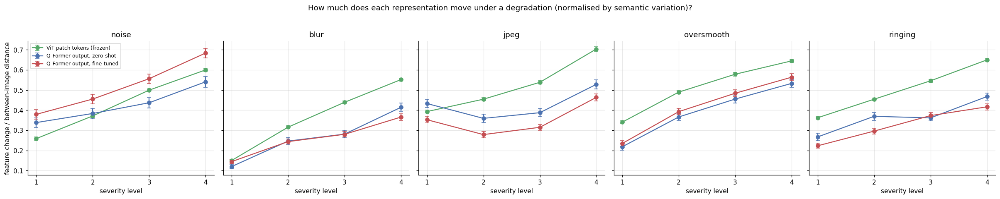

saved /kaggle/working/outputs/figs/bottleneck_sensitivity.png
retention ratio (Q-Former sensitivity / ViT sensitivity; <1 = bottleneck attenuates the degradation):
 model       Q-Former output, fine-tuned  Q-Former output, zero-shot
dist                                                               
blur                              0.759                       0.743
jpeg                              0.689                       0.841
noise                             1.236                       1.029
oversmooth                        0.801                       0.751
ringing                           0.648                       0.733


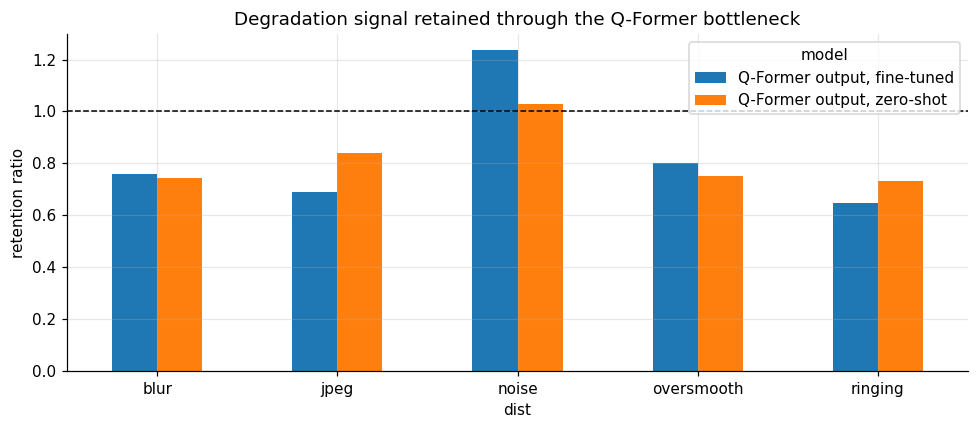

saved /kaggle/working/outputs/figs/bottleneck_retention.png
[time] Feature sensitivity: ViT vs Q-Former: 1.5s

==================== Linear probes: can the degradation be decoded? ====================
                 space                    task    acc    std
0         ViT (frozen)            type (6-way)  0.953  0.020
1         ViT (frozen)  type+severity (21-way)  0.761  0.021
2   Q-Former zero-shot            type (6-way)  0.844  0.008
3   Q-Former zero-shot  type+severity (21-way)  0.557  0.031
4  Q-Former fine-tuned            type (6-way)  0.896  0.006
5  Q-Former fine-tuned  type+severity (21-way)  0.632  0.029


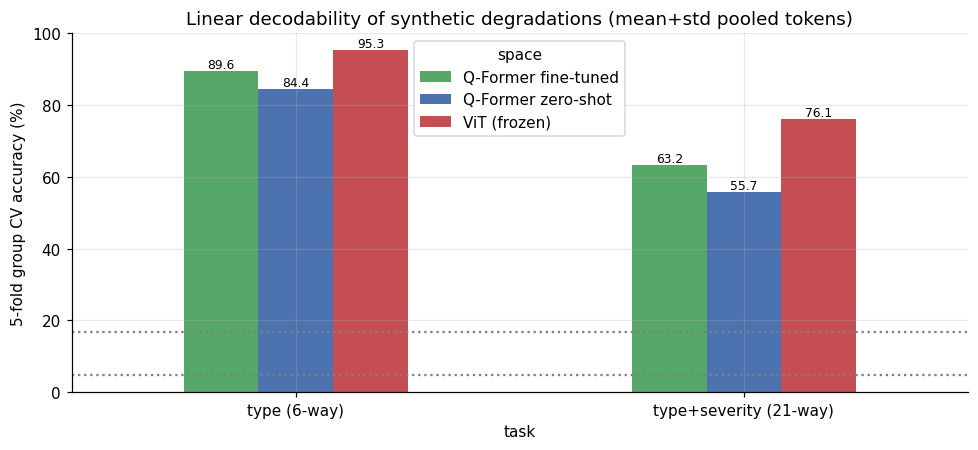

saved /kaggle/working/outputs/figs/bottleneck_linear_probes.png
[time] Linear probes: can the degradation be decoded?: 7.4s

==================== Psychometric curves: P(yes) vs severity ====================


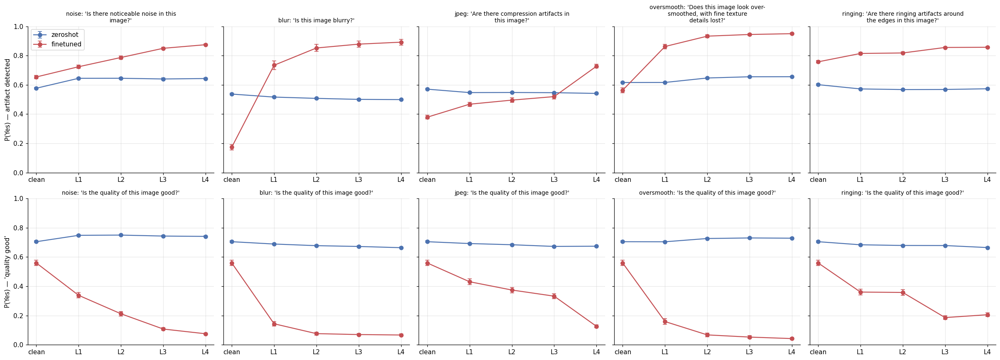

saved /kaggle/working/outputs/figs/psychometric_curves.png
detect_gain = P(yes|L4) - P(yes|clean) on the artifact question; quality_drop = P(good|clean) - P(good|L4):
           detect_gain          quality_drop         
model        finetuned zeroshot    finetuned zeroshot
dist                                                 
blur             0.718   -0.038        0.492    0.041
jpeg             0.348   -0.029        0.433    0.031
noise            0.220    0.066        0.484   -0.036
oversmooth       0.386    0.040        0.517   -0.024
ringing          0.100   -0.028        0.354    0.040
[time] Psychometric curves: P(yes) vs severity: 2.0s


In [22]:
# ---------------------------------------------------------------- 7.3 Bottleneck analysis (the mid-fusion-specific question)
with section("Feature sensitivity: ViT vs Q-Former"):
    sz = probe_zs[0]
    curves = [("ViT patch tokens (frozen)", sz[sz.space == "vit"]), ("Q-Former output, zero-shot", sz[sz.space == "qf"])]
    if probe_ft is not None:
        sf = probe_ft[0]
        curves.append(("Q-Former output, fine-tuned", sf[sf.space == "qf"]))
    fig, axes = plt.subplots(1, len(DIST_NAMES), figsize=(22, 4.2), sharey=True)
    for a, kind in zip(axes, DIST_NAMES):
        for (lab, d), c in zip(curves, ["#55A868", "#4C72B0", "#C44E52"]):
            g = d[d.dist == kind].groupby("level").norm_sens.agg(["mean", "sem"])
            a.errorbar(g.index, g["mean"], yerr=g["sem"], marker="o", capsize=3, label=lab, color=c)
        a.set_title(kind); a.set_xlabel("severity level"); a.set_xticks([1, 2, 3, 4])
    axes[0].set_ylabel("feature change / between-image distance"); axes[0].legend(fontsize=8)
    plt.suptitle("How much does each representation move under a degradation (normalised by semantic variation)?", y=1.03)
    savefig("bottleneck_sensitivity")
    ret = []
    for lab, d in curves[1:]:
        for kind in DIST_NAMES:
            v = sz[(sz.space == "vit") & (sz.dist == kind)].groupby("level").norm_sens.mean()
            q = d[d.dist == kind].groupby("level").norm_sens.mean()
            ret.append(dict(model=lab, dist=kind, retention=float((q / v).mean())))
    ret = pd.DataFrame(ret).pivot(index="dist", columns="model", values="retention")
    print("retention ratio (Q-Former sensitivity / ViT sensitivity; <1 = bottleneck attenuates the degradation):\n", ret.round(3))
    RESULTS["sensitivity_retention"] = ret.round(4).to_dict()
    ret.plot.bar(figsize=(9, 4), rot=0); plt.axhline(1, color="k", ls="--", lw=1); plt.ylabel("retention ratio")
    plt.title("Degradation signal retained through the Q-Former bottleneck")
    savefig("bottleneck_retention")

with section("Linear probes: can the degradation be decoded?"):
    meta = probe_zs[2]
    y_type = meta.dist.values
    y_full = (meta.dist + "-" + meta.level.astype(str)).values
    groups = meta.img.values
    spaces = {"ViT (frozen)": probe_zs[1]["vit"], "Q-Former zero-shot": probe_zs[1]["qf"]}
    if probe_ft is not None:
        spaces["Q-Former fine-tuned"] = probe_ft[1]["qf"]
    pr = []
    for name, X in spaces.items():
        for task, y in [("type (6-way)", y_type), ("type+severity (21-way)", y_full)]:
            m, s = probe_accuracy(X, y, groups)
            pr.append(dict(space=name, task=task, acc=m, std=s))
    pr = pd.DataFrame(pr)
    print(pr.round(3))
    RESULTS["linear_probes"] = pr.round(4).to_dict("records")
    pv = pr.pivot(index="task", columns="space", values="acc") * 100
    ax = pv.plot.bar(figsize=(9, 4.2), rot=0, color=["#55A868", "#4C72B0", "#C44E52"][:pv.shape[1]])
    ax.axhline(100 / 6, ls=":", color="gray"); ax.axhline(100 / 21, ls=":", color="gray")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f", fontsize=8)
    ax.set_ylabel("5-fold group CV accuracy (%)"); ax.set_title("Linear decodability of synthetic degradations (mean+std pooled tokens)")
    savefig("bottleneck_linear_probes")

with section("Psychometric curves: P(yes) vs severity"):
    ps = pd.concat([p_[3] for p_ in (probe_zs, probe_ft) if p_ is not None])
    fig, axes = plt.subplots(2, len(DIST_NAMES), figsize=(22, 8), sharey=True)
    for j, kind in enumerate(DIST_NAMES):
        for mname, c in [("zeroshot", "#4C72B0"), ("finetuned", "#C44E52")]:
            d = ps[ps.model == mname]
            if len(d) == 0:
                continue
            spec = pd.concat([d[(d.question == kind) & (d.dist == "clean")], d[(d.question == kind) & (d.dist == kind)]])
            g = spec.groupby("level").p_yes.agg(["mean", "sem"])
            axes[0, j].errorbar(g.index, g["mean"], yerr=g["sem"], marker="o", capsize=3, color=c, label=mname)
            qual = pd.concat([d[(d.question == "quality") & (d.dist == "clean")], d[(d.question == "quality") & (d.dist == kind)]])
            g = qual.groupby("level").p_yes.agg(["mean", "sem"])
            axes[1, j].errorbar(g.index, g["mean"], yerr=g["sem"], marker="o", capsize=3, color=c, label=mname)
        axes[0, j].set_title(f"{kind}: '{wrap(PSY_Q[kind], 34)}'", fontsize=9)
        axes[1, j].set_title(f"{kind}: '{QUALITY_Q}'", fontsize=9)
        for i in range(2):
            axes[i, j].set_xticks(range(5)); axes[i, j].set_xticklabels(["clean", "L1", "L2", "L3", "L4"]); axes[i, j].set_ylim(0, 1)
    axes[0, 0].set_ylabel("P(Yes) — artifact detected"); axes[1, 0].set_ylabel("P(Yes) — 'quality good'"); axes[0, 0].legend()
    savefig("psychometric_curves")
    sl = []
    for mname in ps.model.unique():
        d = ps[ps.model == mname]
        for kind in DIST_NAMES:
            c0 = d[(d.question == kind) & (d.dist == "clean")].p_yes.mean()
            c4 = d[(d.question == kind) & (d.dist == kind) & (d.level == 4)].p_yes.mean()
            q0 = d[(d.question == "quality") & (d.dist == "clean")].p_yes.mean()
            q4 = d[(d.question == "quality") & (d.dist == kind) & (d.level == 4)].p_yes.mean()
            sl.append(dict(model=mname, dist=kind, detect_gain=c4 - c0, quality_drop=q0 - q4))
    sl = pd.DataFrame(sl)
    print("detect_gain = P(yes|L4) - P(yes|clean) on the artifact question; quality_drop = P(good|clean) - P(good|L4):")
    print(sl.pivot(index="dist", columns="model", values=["detect_gain", "quality_drop"]).round(3))
    RESULTS["psychometric"] = sl.round(4).to_dict("records")

In [23]:
# ---------------------------------------------------------------- 8. Final summary (paste-ready for the report)
def pct(x):
    return "—" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{100 * x:.2f}"

lines = ["# BLIP-2 (mid-fusion) — results summary — all experiments", "",
         f"- Experiments finished: {list(RUNS)} | skipped (time): {SKIPPED or 'none'}",
         f"- Sections below (until 'All experiments') describe the PRIMARY run `{PRIMARY}`", "",
         f"- Mode: {'SMOKE TEST' if SMOKE_TEST else 'full run'} | LLM precision: {QUANT_MODE} | total notebook time: {(time.time() - T0_NOTEBOOK) / 60:.1f} min",
         f"- Trainable params: {RESULTS['training_setup']['trainable_M']:.2f}M ({RESULTS['training_setup']['trainable_pct']:.2f}% of {RESULTS['training_setup']['total_M']:.0f}M)",
         f"- Training: {RESULTS['training']['steps']} steps, {RESULTS['training']['samples_seen']:,} samples, {RESULTS['training']['minutes']:.1f} min; "
         f"val loss {RESULTS['training']['val_before']['val_loss']:.3f} -> {RESULTS['training']['val_after']['val_loss']:.3f}",
         f"- Q-Bench dev: n = {len(qb)}, chance = {pct(CHANCE)}%", "",
         "| Setting | Overall | Yes/No | What | How | Global dist. | Global other | Local dist. | Local other |",
         "|---|---|---|---|---|---|---|---|---|"]
for key, name in [("qbench_zeroshot", "Zero-shot"), ("qbench_finetuned", "Fine-tuned"),
                  ("qbench_zeroshot_blind", "Zero-shot (gray image)"), ("qbench_finetuned_blind", "Fine-tuned (gray image)")]:
    r = RESULTS.get(key)
    if r:
        cols = ["overall", "qtype:Yes/No", "qtype:What", "qtype:How", "concern:Global distortion", "concern:Global other",
                "concern:Local distortion", "concern:Local other"]
        lines.append(f"| {name} | " + " | ".join(pct(r.get(c)) for c in cols) + " |")
if "significance" in RESULTS:
    s = RESULTS["significance"]
    lines += ["", f"- FT − ZS: {100 * s['delta']:+.2f} pts (95% CI {100 * s['delta_ci'][0]:+.2f} … {100 * s['delta_ci'][1]:+.2f}); "
                  f"McNemar fixed={s['fixed']}, broken={s['broken']}, p={s['mcnemar_p']:.2e}"]
if "visual_reliance" in RESULTS:
    lines.append(f"- Visual reliance (acc − blind acc): ZS {100 * RESULTS['visual_reliance']['zeroshot']:+.2f} pts, "
                 f"FT {100 * RESULTS['visual_reliance']['finetuned']:+.2f} pts")
if "linear_probes" in RESULTS:
    lines += ["", "| Linear probe | " + " | ".join(sorted({r['space'] for r in RESULTS['linear_probes']})) + " |",
              "|---|" + "---|" * len({r['space'] for r in RESULTS['linear_probes']})]
    for task in ["type (6-way)", "type+severity (21-way)"]:
        d = {r["space"]: r["acc"] for r in RESULTS["linear_probes"] if r["task"] == task}
        lines.append(f"| {task} | " + " | ".join(pct(d[k]) for k in sorted(d)) + " |")
if "sensitivity_retention" in RESULTS:
    lines += ["", "Retention ratio (Q-Former / ViT normalised sensitivity):", "```", pd.DataFrame(RESULTS["sensitivity_retention"]).round(3).to_string(), "```"]
def pm(series, scale=100.0, digits=1):
    s_ = pd.Series(series).dropna().astype(float) * scale
    if len(s_) == 0:
        return "—"
    return f"{s_.mean():.{digits}f}" if len(s_) == 1 else f"{s_.mean():.{digits}f} ± {s_.std(ddof=1):.{digits}f}"

if len(RUNS):
    pr_ = pd.DataFrame([run_row(n, R) for n, R in RUNS.items()])
    lines += ["", "## All experiments (Q-Bench dev %, mean ± std over seeds where n > 1)", "",
              f"Zero-shot: {pct(RESULTS['qbench_zeroshot']['overall'])}% overall", "",
              "| Setting | n | Overall | Yes/No | What | How | Grey image | Visual reliance | Probe 6-way | Probe 21-way | Trainable (M) |",
              "|---|---|---|---|---|---|---|---|---|---|---|"]
    for s_name in SETTING_ORDER:
        g_ = pr_[pr_.setting == s_name]
        if len(g_) == 0:
            continue
        cells = [pm(g_[c]) if c in g_ else "—" for c in ["overall", "yesno", "what", "how", "blind", "visual_reliance", "probe6", "probe21"]]
        lines.append(f"| {s_name} | {len(g_)} | " + " | ".join(cells) + f" | {g_.trainable_M.mean():.1f} |")
    ret_c, det_c = [f"ret_{d}" for d in DIST_NAMES], [f"det_{d}" for d in DIST_NAMES]
    lines += ["", "Retention ratio (Q-Former / ViT; <1 = attenuated) and detection gain P(yes|L4) − P(yes|clean):", "",
              "| Setting | " + " | ".join(f"ret {d}" for d in DIST_NAMES) + " | " + " | ".join(f"det {d}" for d in DIST_NAMES) + " |",
              "|---|" + "---|" * (2 * len(DIST_NAMES)),
              "| zero-shot | " + " | ".join(f"{ZS_REF['retention'].get(d, float('nan')):.2f}" for d in DIST_NAMES) + " | " +
              " | ".join(f"{p['detect_gain']:+.2f}" for p in ZS_REF["psychometric"]) + " |"]
    for s_name in SETTING_ORDER:
        g_ = pr_[pr_.setting == s_name]
        if len(g_) == 0:
            continue
        lines.append(f"| {s_name} | " + " | ".join(pm(g_[c], 1.0, 2) if c in g_ else "—" for c in ret_c + det_c) + " |")
    vs_ = RESULTS.get("aggregate", {}).get("vs_primary", [])
    if vs_:
        lines += ["", f"Paired comparison with the primary run `{PRIMARY}` (same questions):", "",
                  "| Run | Δ acc (pts) | 95% CI | fixed | broken | McNemar p |", "|---|---|---|---|---|---|"]
        for v_ in vs_:
            lines.append(f"| {v_['run']} | {100 * v_['delta']:+.2f} | [{100 * v_['delta_ci'][0]:+.2f}, {100 * v_['delta_ci'][1]:+.2f}] | "
                         f"{v_['fixed']} | {v_['broken']} | {v_['mcnemar_p']:.3g} |")
    lines += ["", "Note: the synthetic-data run is trained on the same distortion generator that the probe images use "
              "(different images and question wording), so its detection gains are an in-distribution check."]
lines += ["", f"- Failed (non-critical) sections: {FAILED_SECTIONS if FAILED_SECTIONS else 'none'}",
          "", "Figures: " + ", ".join(sorted(os.path.basename(p) for p in glob.glob(os.path.join(FIG_DIR, '*.png'))))]
summary_md = "\n".join(lines)
with open(os.path.join(OUT_DIR, "summary.md"), "w") as f:
    f.write(summary_md)
RESULTS["failed_sections"] = FAILED_SECTIONS
RESULTS["total_minutes"] = (time.time() - T0_NOTEBOOK) / 60
save_results()
print(summary_md)
print("\nOutput files:")
for p in sorted(glob.glob(os.path.join(OUT_DIR, "**", "*"), recursive=True)):
    if os.path.isfile(p):
        print(f"  {os.path.relpath(p, OUT_DIR):55s} {os.path.getsize(p) / 2**20:8.2f} MB")

# BLIP-2 (mid-fusion) — results summary — all experiments

- Experiments finished: ['seed42_crossattn', 'seed42_none', 'seed42_full', 'seed42_crossattn_synth', 'seed43_crossattn', 'seed44_crossattn'] | skipped (time): none
- Sections below (until 'All experiments') describe the PRIMARY run `seed42_crossattn`

- Mode: full run | LLM precision: 4bit-nf4 | total notebook time: 346.7 min
- Trainable params: 45.67M (1.21% of 3768M)
- Training: 875 steps, 14,000 samples, 40.3 min; val loss 3.434 -> 0.838
- Q-Bench dev: n = 1495, chance = 37.80%

| Setting | Overall | Yes/No | What | How | Global dist. | Global other | Local dist. | Local other |
|---|---|---|---|---|---|---|---|---|
| Zero-shot | 42.41 | 54.55 | 36.50 | 34.28 | 38.72 | 44.68 | 41.45 | 47.35 |
| Fine-tuned | 54.58 | 68.55 | 43.58 | 49.09 | 52.33 | 56.02 | 53.29 | 58.37 |
| Zero-shot (gray image) | 39.87 | 55.09 | 30.53 | 31.44 | 39.11 | 40.97 | 40.79 | 38.37 |
| Fine-tuned (gray image) | 42.54 | 50.55 | 33.63 | 41.78 | 42.41 